# Simulating Human Multi-area Network

The model used here is a **spiking network model of one human cerebral hemisphere**, extending
the **Human Multi-Area Model (HuMAM)** from *Forschungszentrum Julich* with configurable
disease neuron types, oscillatory stimulation, and an analysis pipeline that ends in signals you can put next
to EEG and fMRI.

At full scale the model has **3.47 million neurons** and **42.8 billion synapses**. This tutorial
runs the same model but downscaled by a factor of 100, on a laptop, and then shows you how to send
the large-scale version to a cluster.

The original code by Pronold et al. is at:
https://github.com/INM-6/human-multi-area-model

---

### Objectives

1. Understand the model
2. Read and edit an experiment file - the model's entire control panel
3. Run the full three-stage pipeline on a healthy cortex
4. Read the ~200 figures it produces
5. Plug in your own data - a connectome, a pathology map, your own neuron parameters
6. Read a full-scale result computed on a cluster next to your laptop run

Appendix B: an amyloid-burdened cortex, from an amyloid-PET map to a healthy-vs-amyloid
experiment and a seed check.

**If you run into a problem, raise your hand!**

---
## Part 0 - Quick start

### 0.1 Get your environment ready

The repository ships the environment as `environment.yaml`. Create it with one command, either

```shell
mamba env create -f environment.yaml
```

or

```shell
conda env create -f environment.yaml
```

Then activate it and register it as the Jupyter kernel this notebook is saved against:

```shell
mamba activate nest3.8        # or: conda activate nest3.8
python -m ipykernel install --user --name nest3.8 --display-name "nest3.8"
```

### 0.2 Does NEST work on my machine?

If the pre-compiled NEST package installed properly, this simple test passes. Run
`python -c "import nest"`; you should see something like this:

```shell
              -- N E S T --
  Copyright (C) 2004 The NEST Initiative

 Version: 3.8.0
 Built: May  5 2025 12:54:52

 This program is provided AS IS and comes with
 NO WARRANTY. See the file LICENSE for details.

 Problems or suggestions?
   Visit https://www.nest-simulator.org

 Type 'nest.help()' to find out more about NEST.
```

The check cell at the end of this part (0.4) prints the same banner, followed by the setup it found:

```shell
bundled model   : /path/to/repo/model
Results go to   : /path/to/repo/results
NEST            : 3.8.0
numpy / pandas  : 2.2.6 / 2.2.3
CPU cores       : 16
```

Congratulations! A NEST build without MPI is installed and working.

### 0.3 It looks like it crashed?

A spiking simulation's memory is dominated by **synapses**, not neurons. Measured on this model
(Apple Silicon, NEST 3.8, 4 threads):

```
peak RAM  ~=  0.4 GB  +  128 bytes x (number of synapses)
```

**Laptop notes: plug in - both macOS and Windows down-clock hard on battery.**
Expect fans: at the default size, NEST's simulation of the 4 s run alone takes 30-70 s of
full-throttle multicore compute, and a whole pipeline run about 6.5 minutes. These times are for an
otherwise idle machine; other heavy jobs can easily double them. **If a cell runs much longer than
the time its comment gives on an idle machine, you are probably swapping; stop it and consider a
smaller network (Part 2)**.

### 0.4 Final check
Before you click **Run All**, check that the notebook uses **the right kernel (nest3.8)**. Then run
the cell below.

In [1]:
# One-click check
# This is supposed to exit without error.

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Everything that is bookkeeping rather than model - where the tutorial, the
# bundled model and the results live, how a stage is launched, how the hash files
# are read back, how a finished run's figures and tables are loaded - lives in
# tools/pipeline.py, so that the cells below stay about the model.
sys.path.insert(0, str(Path.cwd().resolve() / "tools"))
try:
    # Re-read tools/pipeline.py on every run of this cell: Python keeps a module it has
    # imported once, so without the reload an edited pipeline.py only takes effect after
    # a kernel restart.
    import importlib
    import pipeline
    importlib.reload(pipeline)
    from pipeline import (
        TUTORIAL, MODEL_ROOT, EXPERIMENTS, RESULTS,
        check_environment, run_all, hashes, print_hashes,
        run_dir, sim_dir, describe_outputs, show, rates, pop_level,
        area_mean_rate, load_result, amyloid_burden, check_data,
        master_seed, rates_for_seed, eta_search, fullscale_rates,
        has_fullscale, fullscale_info, fullscale_fc, fullscale_estimate, show_figure,
        print_file, print_excerpt,
    )
except ModuleNotFoundError as err:
    raise SystemExit(
        f"{err}\nRun this notebook from the tutorial's own folder - the one that "
        "contains tools/, experiments/ and model/.")

# Checks the bundled model is present and NEST imports, then reports the setup.
check_environment()


              -- N E S T --
  Copyright (C) 2004 The NEST Initiative

 Version: 3.8.0
 Built: May  5 2025 12:54:52

 This program is provided AS IS and comes with
 NO WARRANTY. See the file LICENSE for details.

 Problems or suggestions?
   Visit https://www.nest-simulator.org

 Type 'nest.help()' to find out more about NEST.

bundled model   : /Users/nozomizore1974/Codes/Cortical-Model-Tutorial/model
Results go to   : /Users/nozomizore1974/Codes/Cortical-Model-Tutorial/results
NEST            : 3.8.0
numpy / pandas  : 2.2.6 / 2.2.3
CPU cores       : 16


'3.8.0'

---

# Part 1 - The cortical model

## 1.1 Architecture

```shell
   MACRO   34 cortical areas, Desikan-Killiany atlas, one hemisphere
             |  inter-area connection strength from HCP diffusion tractography
             v
   MESO    4 layers per area (II/III, IV, V, VI)
             |  layer-resolved neuron densities, von Economo & Koskinas
             |  laminar target patterns from predictive connectomics
             v
   MICRO   2 populations per layer: excitatory (E) and inhibitory (I)
             |  leaky integrate-and-fire neurons, exponential synaptic currents
             v
           34 x 4 x 2 = 272 populations, 254 of them non-empty
           3.47 M neurons, 42.8 G internal synapses at full scale
```

Each area is modelled as a **1 mm^2 patch** of cortex with that area's own thickness and cell
density - the classic cortical-column idealisation, repeated 34 times and wired together.

## 1.2 Data

| Ingredient | Source | In the repository |
|---|---|---|
| Layer-resolved **neuron densities** | von Economo & Koskinas cytoarchitectonic atlas, mapped to Desikan-Killiany | `experimental_data/voneconomokoskinas/` |
| **Synapse density** | 6.6e8 per mm^3 (Cano-Astorga et al. 2021) | `model/src/default_net_params.py` |
| **E/I ratio** per layer | Lichtman / Binzegger electron-microscopy counts | `experimental_data/fraction_EI/` |
| **Inter-area connectivity and distances** | HCP diffusion MRI tractography | `experimental_data/hcp_dti/` |
| **Laminar target patterns** | predictive connectomics (Schmidt et al. 2018) | `model/src/data_preprocessing/connectivity.py` |
| **Reference resting-state fMRI** | Senden 7T, 19 participants (preprocessed, no raw scans) | `experimental_data/senden/` |
| **Neuron parameters** | Allen Brain Cell Atlas GLIF fits | the experiment files |
| **Amyloid spatial distribution** | amyloid-PET (ADNI participant), DK-parcellated | `experimental_data/amyloid/` |

Nothing here is fitted to reproduce a target output. That is the whole point: the dynamics are a
*prediction*, and the comparison with EEG or fMRI is the test.

> **For machine learning people**
>
> There is no training set, no loss, no backprop. The
> architecture is measured; the weights follow from a single postsynaptic-potential amplitude plus
> scaling rules. What you tune is a handful of global gains, and you judge the result by whether
> emergent statistics match independent measurements. This is the generative-model tradition, not
> the function-approximation one.

## 1.3 Leaky Integrate-and-Fire Model

Every neuron is a **leaky integrate-and-fire** unit with exponentially decaying synaptic currents
(`iaf_psc_exp` in NEST). Its membrane potential follows

$$\tau_m \frac{dV}{dt} = -(V - E_L) + \frac{\tau_m}{C_m}\, I_{\mathrm{syn}}(t) + \frac{\tau_m}{C_m}\, I_e$$

and when $V$ reaches $V_{\mathrm{th}}$ the neuron emits a spike, is reset to $V_{\mathrm{reset}}$
and held there for a refractory time $t_{\mathrm{ref}}$. Each incoming spike adds a current pulse
that decays with $\tau_{\mathrm{syn}}$.

| Parameter | Excitatory | Inhibitory | Meaning |
|---|---|---|---|
| $E_L$ | -70 mV | -70 mV | resting potential |
| $V_{\mathrm{th}}$ | -45 mV | -45 mV | firing threshold |
| $V_{\mathrm{reset}}$ | -70 mV | -70 mV | post-spike potential |
| $C_m$ | 220 pF | 100 pF | membrane capacitance |
| $\tau_m$ | 10 ms | 10 ms | membrane time constant |
| $\tau_{\mathrm{syn}}$ | 2 ms | 2 ms | synaptic current decay |
| $t_{\mathrm{ref}}$ | 2 ms | 2 ms | refractory period |

The number that matters most below is $V_{\mathrm{th}} - E_L = 25$ mV: **the distance a neuron must
be driven to fire**. Amyloid shrinks it to 15 mV (Appendix B), and downscaling changes how far the drive
actually reaches (Appendix A).

$I_e$ is a constant current. It is zero in the full-scale model and carries the downscaling
compensation otherwise - remember it, it reappears in Appendix A.

## 1.4 Static synapses
A synapse connects one neuron to another. Three things define the recurrent wiring:

- **In-degree** $K_{ij}$ - how many synapses a neuron in population $i$ receives from population
  $j$. At full scale a neuron has about **12 500** recurrent inputs. This is the dominant number in
  the model; everything else is secondary to it.
- **Weight** $J_{ij}$ - specified as a postsynaptic *potential* (0.1 mV for excitatory connections,
  5x larger and negative for inhibitory ones) and converted internally to a current amplitude.
- **Delay** - 1.5 ms locally, and distance divided by a 3.5 mm/ms axonal speed between areas, each
  drawn from a clipped lognormal distribution.

Inter-area connectivity uses **predictive connectomics**: tractography gives the strength of an
area-to-area projection, and the *relative cytoarchitectonic difference* between the two areas
predicts which layers it targets. Areas of similar cell density connect more densely, and the
direction of the density gradient decides whether a projection behaves as feedforward (terminating
in layer IV) or feedback (terminating outside it). `FLN = 0.86` of all synapses stay within an area.

Each population also receives **Poisson background input** standing in for everything outside the
modelled hemisphere - the other hemisphere, thalamus, neuromodulation. Its strength is the parameter
`eta_ext`, expressed as a multiple of the distance to threshold. It is the single most important
dial in the model, and 5.6 is about setting it correctly.

## 1.5 Outcomes

| Simulated signal | How it is built | Experimental counterpart |
|---|---|---|
| **Spike trains** | recorded directly | extracellular unit recordings |
| **Firing rate, CV ISI, Lv** | per population | spike-train statistics from electrode arrays |
| **LFP proxy** | synaptic currents, or spikes convolved with the synaptic kernel | intracranial LFP; the generator of M/EEG |
| **Power spectra, coherence, PLV** | from the LFP proxy | quantitative EEG, MEG connectivity |
| **BOLD** | area firing rate through the Balloon-Windkessel model | fMRI time course |
| **Functional connectivity** | pairwise BOLD correlation | resting-state FC matrix |


---

# Part 2 - Experiment Configuration

An experiment is **one Python file with three dictionaries**. There is no other interface.
Anything you leave out keeps the repository default from `model/src/default_net_params.py`,
`model/src/default_sim_params.py` and `model/src/default_ana_params.py`.

| Dictionary | Fixes |
|---|---|
| `net_params` | size, scaling, drive, connection gains, pathology |
| `sim_params` | simulated duration, seed, recorders, stimulation |
| `ana_params` | analysis windows, which proxies, figure settings |

The split matters because it matches the three pipeline stages, and each stage's output directory is
named by a hash of its own dictionary. On the cluster (Part 6) that is what decides which stages a
change re-runs: change `ana_params` and only the analysis re-runs; change `net_params` and everything
downstream is rebuilt. On the laptop every run rebuilds all three stages from scratch (Part 3).

In [2]:
print_file(EXPERIMENTS / "tutorial_CN.py")

"""Tutorial experiment: healthy (CN) cortex, laptop scale.

An experiment is exactly this: one Python file defining three
dictionaries. Everything not mentioned here keeps the repository default from
``src/default_net_params.py``, ``src/default_sim_params.py`` and
``src/default_ana_params.py``.

The pipeline reads this file three times - once per stage - so it must stay a
plain, side-effect-free description of *what to run*, never of *how to run it*.
"""
import os

# Results go next to the tutorial, never inside the model repository.
_HERE = os.path.dirname(os.path.abspath(__file__))
_RESULTS = os.path.join(os.path.dirname(_HERE), "results")


# ===========================================================================
#  net_params - what the network IS
# ===========================================================================
net_params = {
    "outpath": _RESULTS,
    "mode": "INFO",

    # ---- size -------------------------------------------------------------
    # The full mo

## 2.1 Key parameters


Most defaults you will never touch. These you will:

| Parameter | What it does | Typical values |
|---|---|---|
| `N_scaling` | fraction of neurons kept | 1.0 full, 0.01 here |
| `K_scaling` | fraction of in-degree kept | 1.0 full, 0.1 downscaled |
| `input_params["eta_ext"]` | external drive, in units of the distance to threshold | 1.1 full scale, 5.0 here (5.6) |
| `scaling_factors_recurrent["cc_scalingEtoE"]` | gain on long-range excitation | 2.5 (repository default); 1.0-3.0, higher = more inter-area coupling, closer to instability |
| `scaling_factors_recurrent["cc_scalingEtoI"]` | gain on long-range excitation onto interneurons | 5.0 (repository default), usually 2x the E->E value; what keeps the network stable |
| `neuron_types` | custom neuron types (e.g. amyloid-affected), each with its fraction and parameters | `{}`, or `{name: {"ratio_E": scalar / dict / PET-derived CSV, ...}}` |
| `t_sim` | simulated biological time | 4000 ms here; 10-100 s on a cluster |
| `master_seed` | the random draw | any integer - **change it to measure your own noise floor** |
| `rec_dev` | recorders | `["spike_recorder"]`; add `"I_syn"` for an exact LFP at a large disk cost |
| `stimuli` | oscillatory current injection | `ac_generator` per `(area, layer, population)` |

## 2.2 Choosing a size for your machine

`N_scaling` and `K_scaling` are **not** interchangeable:

- lowering **`K_scaling`** changes the dynamics - each neuron sees fewer inputs - and must be
  compensated (Appendix A);
- lowering **`N_scaling`** mostly adds finite-size noise and leaves the mean-field behaviour intact.

So the right way to fit the model onto a laptop is to hold `K_scaling` at the value the project
validates (0.1) and push `N_scaling` down. Edit `experiments/tutorial_CN.py` if the default does not
fit your machine:

| `N_scaling` | `K_scaling` | Neurons | Synapses | Peak RAM (predicted / measured) | Simulate 5 s |
|---|---|---|---|---|---|
| 0.002 | 0.1 | 6.9 k | 8.6 M | 1.4 GB / 1.3 GB | ~7 s |
| 0.005 | 0.1 | 17 k | 21 M | 2.9 GB / 3.1 GB | ~19 s |
| **0.01** (default) | **0.1** | **34.7 k** | **42.8 M** | **5.9 GB / -** | 30-70 s (4 s run) |
| 0.02 | 0.1 | 69 k | 86 M | 10.6 GB / - | ~75 s |
| 0.1 | 0.1 | 347 k | 428 M | 55 GB / 81 GB | - |
| 1.0 | 1.0 | 3.47 M | 42.8 G | ~5 TB / 1.6 TB | cluster only |

---

# Part 3 - Running the Model

Every run is the same three commands, each consuming the experiment file and producing a
hash-named directory:

| Stage | Does | Outputs | Cost here |
|---|---|---|---|
| **1. network** | reads the anatomical data, builds neuron numbers, the connectome, weights and delays, applies downscaling and its DC compensation | `results/<run>/<net_hash>/` | ~110 s |
| **2. simulate** | instantiates the network in NEST, connects it, injects Poisson background and any stimuli, integrates at 0.1 ms | `results/<run>/<net_hash>/<sim_hash>/spikes/` | ~85 s |
| **3. analyse** | runs `fullAnalysis()`: spike statistics, LFP proxy, coherence, PLV, BOLD, functional connectivity, and ~200 figures | `results/<run>/<net_hash>/<sim_hash>/<ana_hash>/` | ~180 s |

The costs are measured on a 16-core laptop with 4 threads: a whole run takes about 6.5 minutes.

The notebook calls these three through thin wrappers in `tools/pipeline.py` - stage launching, the hash files, and loading a finished run's output. That module is bookkeeping only; the model is in `model/`.

**On the laptop nothing is reused.** `run_all("tutorial_CN")` empties `results/tutorial_CN/` and runs
all three stages again, every time - no stage is skipped because its hash already exists, and no
table is read back from an earlier run. Each run has its own directory, so two experiments never
share output either. A run costs minutes here, and in exchange every figure below is guaranteed to
come from the experiment file as it is now. Skipping finished stages is worth its bookkeeping only
when a stage costs hours: that is the cluster workflow of Part 6.


In [3]:
# The pipeline helpers are already imported (cell 1). There is no magic in them:
# run_all() empties the run's directory, writes a two-line driver that points the
# experiment's output there, and calls run_stage() once per stage. run_stage() is
# one subprocess call, run from the model folder, with the experiment file and the
# hash files as its arguments - exactly what the Snakefile in Part 6 issues on a
# cluster. The wrappers only time the calls, keep every output outside model/, and
# raise if a stage fails.
import inspect
import pipeline

print(inspect.getsource(pipeline.run_all))
print(inspect.getsource(pipeline.run_stage))


def run_all(experiment, stages=STAGES, threads=4, quiet=False, title=None,
            seed=None):
    """Run `experiment` from scratch: wipe its run directory, then every stage.

    The run is called `experiment`, or ``<experiment>_seed<seed>`` when `seed`
    replaces the experiment's ``master_seed``.  Whatever an earlier run left in
    ``results/<run>/`` is deleted first, so every number and figure read back
    afterwards was produced by this call.  Each line printed is one stage: its
    time and the hash it wrote.  Returns the run's name.
    """
    run = experiment if seed is None else f"{experiment}_seed{seed}"
    root = RESULTS / run
    shutil.rmtree(root, ignore_errors=True)
    (root / "log").mkdir(parents=True)
    _write_driver(experiment, root, seed)

    if not quiet:
        print(title or run)
    total = sum(run_stage(stage, run, threads=threads, quiet=quiet)
                for stage in stages)
    if not quiet:
        print(f"  {'total':9s} {total:6.1f} s")
  

In [4]:
# ~6.5 minutes, from scratch every time. Each stage prints its time and the hash it
# wrote as it finishes; detailed logs are in results/tutorial_CN/log/.
run_all("tutorial_CN", title="tutorial_CN  (healthy cortex)")

# The hashes now appear per stage above. To list them again at any later point:
# print_hashes("tutorial_CN")

tutorial_CN  (healthy cortex)
  network    125.1 s   6d609b28b6cc61d225b16b98946e7727
  simulate   283.3 s   d70206d813a35d219879685916eec6a0
  analyse    211.8 s   746347cf3611cfcd5bfca8f110009de2
  total      620.2 s


'tutorial_CN'

In [5]:
# What the pipeline produced.
describe_outputs("tutorial_CN")

analysis directory: results/tutorial_CN/6d609b28b6cc61d225b16b98946e7727/d70206d813a35d219879685916eec6a0/746347cf3611cfcd5bfca8f110009de2

28 summary figures, e.g.
    binned_spikerates_per_neuron_area_resolved.png
    bold_correlation.png
    bold_overview.png
    boxplot.png
    cc.png
    cv_isi.png

5 per-area figure sets:
    lfp/  (34 areas)
    psd/  (34 areas)
    raster/  (34 areas)
    spectrogram/  (34 areas)
    wavelet/  (34 areas)

10 result files you can load directly:
    bold_signal.pkl
    input_current.pkl
    lfp_area_coherence.pkl
    lfp_area_correlation.pkl
    lfp_coherence.pkl
    lfp_plv.pkl
    lfp_proxy_area.pkl
    lfp_proxy_kernel.pkl
    rate_histogram.pkl
    rate_histogram_areas.pkl

total 97 MB


---

# Part 4 - Reading the Output

The analysis stage produced roughly 200 figures. This part walks the ones that matter, in the order
you should consult them. **The text comes first** (4.1-4.6); **the figures follow** in the same
order, one cell each, labelled Figure 4.1-4.9. Read a section, then run the figures it names.

**The order is not arbitrary.** Figures 4.1-4.3 tell you whether the run is worth interpreting at
all. Only if they look right do the rest mean anything.

What the model is built to get right is the **spiking dynamics** - rates, irregularity and synchrony
of populations of single neurons - and that is where it can be held against electrophysiology (4.1).
The LFP proxy, BOLD and functional connectivity are computed from the same spikes by the pipeline's
analysis toolbox (4.4, 4.5): use them to compare conditions on the same model, not as validated
predictions of an EEG or an fMRI scan.

## 4.1 Check first: is the network in a sensible state?

Three questions, in this order. Each has a counterpart in recordings from awake cortex, and this is
where the model is meant to agree with physiology:

1. **Are the rates plausible?** (Figure 4.1, panel D of Figure 4.2, Figure 4.3) In vivo most
   excitatory neurons fire sparsely, at a few spikes/s or less (Barth & Poulet 2012), and
   fast-spiking interneurons several times faster (Gentet et al. 2010). The target bands used here are
   E 3-5 Hz and I 5-15 Hz.
2. **Is the firing irregular?** (panel E, Figure 4.3) Cortical neurons fire at random-looking
   intervals, with a coefficient of variation (CV) of the inter-spike interval near 1 (Softky & Koch
   1993). Expect 0.7-1.0; much below 0.5 means clock-like firing.
3. **Are neurons decorrelated?** (panel F) Pairwise spike-count correlations in cortex are close to
   zero, of order 0.01 (Ecker et al. 2010; Renart et al. 2010). Large positive values mean the
   population is being driven together, which in this model usually signals instability rather than
   a discovery.

Together these define the **asynchronous irregular state** of balanced excitation and inhibition
(van Vreeswijk & Sompolinsky 1996; Brunel 2000) - the state the network should be in at rest.

**Reading Figure 4.2**, the pipeline's summary figure. Panels **A-C** are raster plots of three areas
over the last second: each dot is a spike, rows are neurons grouped by layer and type (blue
excitatory, red inhibitory). You want a sprinkle of pepper, not vertical stripes. Panel **D** is the
distribution of firing rates per population, **E** the CV of the inter-spike intervals, **F** the
pairwise correlation coefficients. The three areas look different, and should: areas differ in
thickness, cell density and how strongly they are embedded in the connectome, so they sit at
different operating points.

**Reading Figure 4.3**, the same split by layer and cell type, pooled over all 34 areas. Two things to
check. **Inhibitory populations fire several times faster than the excitatory ones of the same
layer** - if not, inhibition is not doing its job. And **the layers differ**: in recordings layer V
pyramidal cells fire most and layer II/III cells least (de Kock et al. 2007; Sakata & Harris 2009),
an ordering the cortical microcircuit this model inherits from reproduces (Potjans & Diesmann 2014).
Which layer leads here depends on the working point, so it is one way to tell whether `eta_ext` and
the connection gains put the model where you intended.

## 4.2 Where is the activity, anatomically?

Figure 4.4 has one panel per area, all on the same vertical scale, showing the population rate over
time. It is the figure to use when you want to know *which areas* a manipulation affected - Appendix B
does exactly that, for an amyloid-burdened cortex. A flat trace means a steady asynchronous state.
Slow drifts shared across many areas would indicate a global oscillation, which at this network size
is more often a sign of trouble than of biology.

## 4.3 What a downscaled network can and cannot tell you

Everything in this part comes from a network with 1% of the neurons and a tenth of the inputs per
neuron (Part 2). It is a different network from the full-scale one, made to resemble it in one
respect. Keep the following in mind before you carry a laptop result over to the full model - Part 6
shows a full-scale run for comparison:

- **Only the mean input is restored.** Each neuron receives a tenth of the synapses, each
  $\sqrt{10} \approx 3.2$ times stronger, plus a DC current for the lost mean (Appendix A). Rates can
  match the full-scale working point; correlations, synchrony and the size of the fluctuations need
  not (van Albada et al. 2015).
- **The working point is set by calibration.** The DC current is computed from full-scale rates that
  the downscaled network itself estimates (5.6). The result is a self-consistent state of the
  downscaled network, not a measurement of the full-scale one.
- **Populations are small.** With 1% of the neurons the smallest populations have a few dozen neurons
  or fewer. Their rates are noisy, and a raster shows only a handful of rows for them.
- **Some states exist only in the full network.** At full scale the network can settle into, and
  switch between, collective states - synchronous bursting in some areas, quiet asynchronous firing in
  all of them - that depend on the individual connectome (6.2). A downscaled network calibrated to the
  asynchronous state does not show them, and one that shows them may do so for reasons of its own.
- **Seconds, not minutes.** The run lasts a few seconds. That suffices for rates and spike statistics,
  is marginal for spectra and coherence, and is far too short for BOLD (4.5).
- **One seed is one sample.** Another `master_seed` draws another network with the same statistics;
  an effect smaller than the seed-to-seed spread is not an effect (B.7).

## 4.4 Rhythms and synchrony: the LFP toolbox

Spikes are not what an EEG measures. That signal is generated by **transmembrane currents**, dominated
by synaptic currents in pyramidal dendrites. The pipeline therefore includes a toolbox that turns the
simulated spikes into an LFP proxy and analyses it the way field recordings are analysed:

| Figure | Tool | Computes |
|---|---|---|
| 4.5 | LFP proxy and its power spectrum | the synaptic currents entering each population (excitatory input as a sink, inhibitory as a source), combined as the reference weighted sum of Mazzoni et al. (2015) - the excitatory current delayed by 6 ms, minus 1.65 times the inhibitory one - z-scored per `(area, layer)`, and their spectrum per area |
| 4.6 | spectrogram | the same spectrum over time, one panel per layer |
| 4.7 | coherence | magnitude-squared coherence between the area-level proxies of every pair of areas |

These figures show what the toolbox produces; they are not results to be held against a patient's
EEG. Read them as such:

- The proxy is z-scored, so only its *shape* is meaningful, never its absolute amplitude. There is no
  forward model - no volume conduction, no scalp - so absolute band power is not comparable to
  clinical qEEG numbers; differences between conditions on the same proxy are.
- **The model has no thalamus**, and cortical alpha depends heavily on thalamocortical loops. In Figure 4.5
  the power rises with frequency into a broad band in the gamma range, without a sharp peak. Such
  high-frequency power is usually attributed to the excitatory-inhibitory feedback loop present in
  every layer (pyramidal-interneuron gamma); where it sits moves with rates, weights and thresholds.
- Check Figure 4.6 first: bands that appear and disappear mean the network is drifting between states,
  and a spectrum averaged over the whole window is then meaningless.
- Coherence (Figure 4.7) measures how consistently two areas keep a fixed phase relationship,
  frequency by frequency. `lfp_plv_fulllayer.png` measures phase locking independently of amplitude;
  `lfp_coherence_fulllayer.png` and the per-layer versions resolve the layers. A few seconds of a
  downscaled network make all of these estimates noisy (4.3).

The per-area versions of every LFP figure live in `plots/lfp/`, `plots/psd/`, `plots/spectrogram/`
and `plots/wavelet/` - 34 areas each.

## 4.5 BOLD and functional connectivity: tools for long runs

The pipeline also bridges to fMRI timescales. A **Balloon-Windkessel model** (Buxton et al. 1998)
turns each area's activity into a BOLD signal (Figure 4.8, top), and correlating the areas pairwise
gives a simulated functional connectivity (FC) matrix - from the BOLD signals (`bold_correlation.png`)
and from the areas' synaptic input currents (`simulated_fc.png`, Figure 4.8, bottom). Both are scored
against an empirical FC matrix (`experimental_fc.png`, by default the Senden 7T group average; 5.3),
and `correlations.txt` holds the scores.

These are tools for runs of minutes. The BOLD signal responds over seconds, so a run of a few seconds
holds little more than its onset, and the matrices of this run demonstrate the pipeline rather than
the model; their agreement with the empirical FC says nothing either way. A meaningful comparison
needs, in order of importance, much longer runs (100 s+), full or near-full scale, and several seeds -
cluster jobs (Part 6).

## 4.6 The numbers behind the figures

Every figure has a data file next to it, so you never have to re-derive anything:

| File | Contains |
|---|---|
| `rates.pkl` | firing rate per population *(next to the spikes, one level up)* |
| `lfp_proxy_kernel.pkl` | LFP proxy, `(area, layer)` x time |
| `lfp_coherence.pkl`, `lfp_plv.pkl` | coherence and phase-locking matrices |
| `lfp_proxy_area.pkl`, `lfp_area_correlation.pkl` | area-level LFP and its correlation matrix |
| `bold_signal.pkl` | BOLD time course per area |
| `rate_histogram.pkl`, `rate_histogram_areas.pkl` | binned population rates |
| `input_current.pkl` | area-averaged synaptic input current |

All are pandas objects; `pd.read_pickle` is all you need. Figure 4.9 loads two of them.

In [6]:
# Figure 4.1 - the mean rates, as numbers (4.1)
# show(), rates() and the hash-to-directory lookup come from tools/pipeline.py.
r = rates("tutorial_CN")
pop = pop_level(r)
print(f"mean excitatory rate : {r.xs('E', level=pop).mean():6.2f} Hz   (target 3-5)")
print(f"mean inhibitory rate : {r.xs('I', level=pop).mean():6.2f} Hz   (target 5-15)")
print(f"silent populations   : {(r == 0).sum()} of {len(r)}")
print(f"fastest population   : {r.idxmax()}  at {r.max():.1f} Hz")

mean excitatory rate :   3.54 Hz   (target 3-5)
mean inhibitory rate :  13.41 Hz   (target 5-15)
silent populations   : 66 of 254
fastest population   : ('postcentral', 'VI', 'I')  at 57.6 Hz


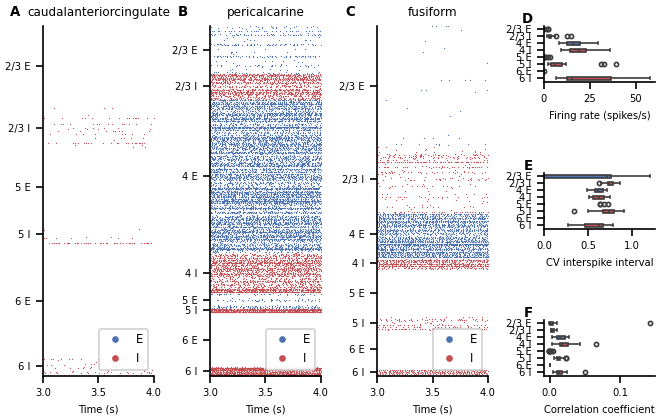

In [7]:
# Figure 4.2 - the summary figure: rasters and spike statistics (4.1)
show("tutorial_CN", "figure_spike_statistics.png", width=980)

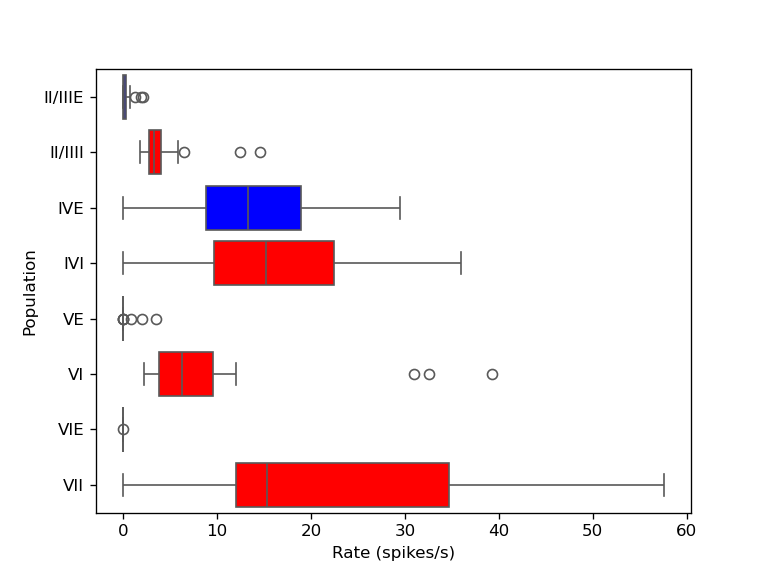

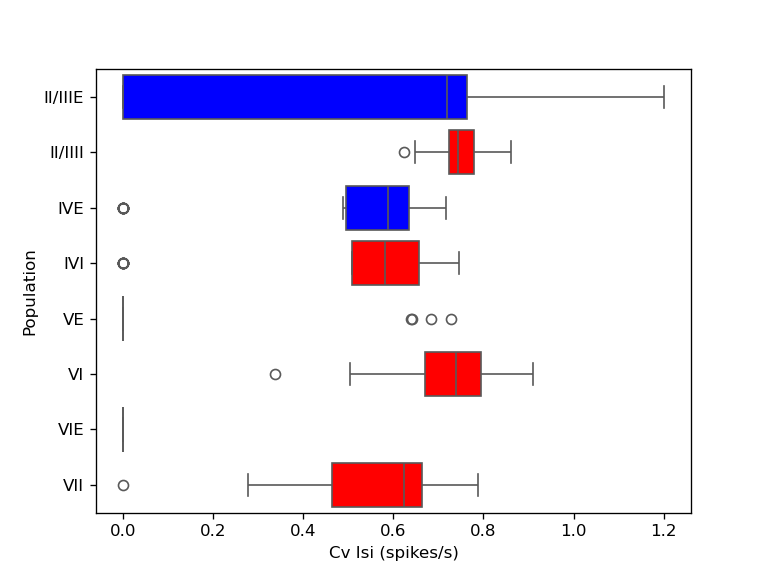

In [8]:
# Figure 4.3 - rates and irregularity, by layer and cell type (4.1)
show("tutorial_CN", "boxplot.png", width=620)
show("tutorial_CN", "cv_isi.png", width=620)

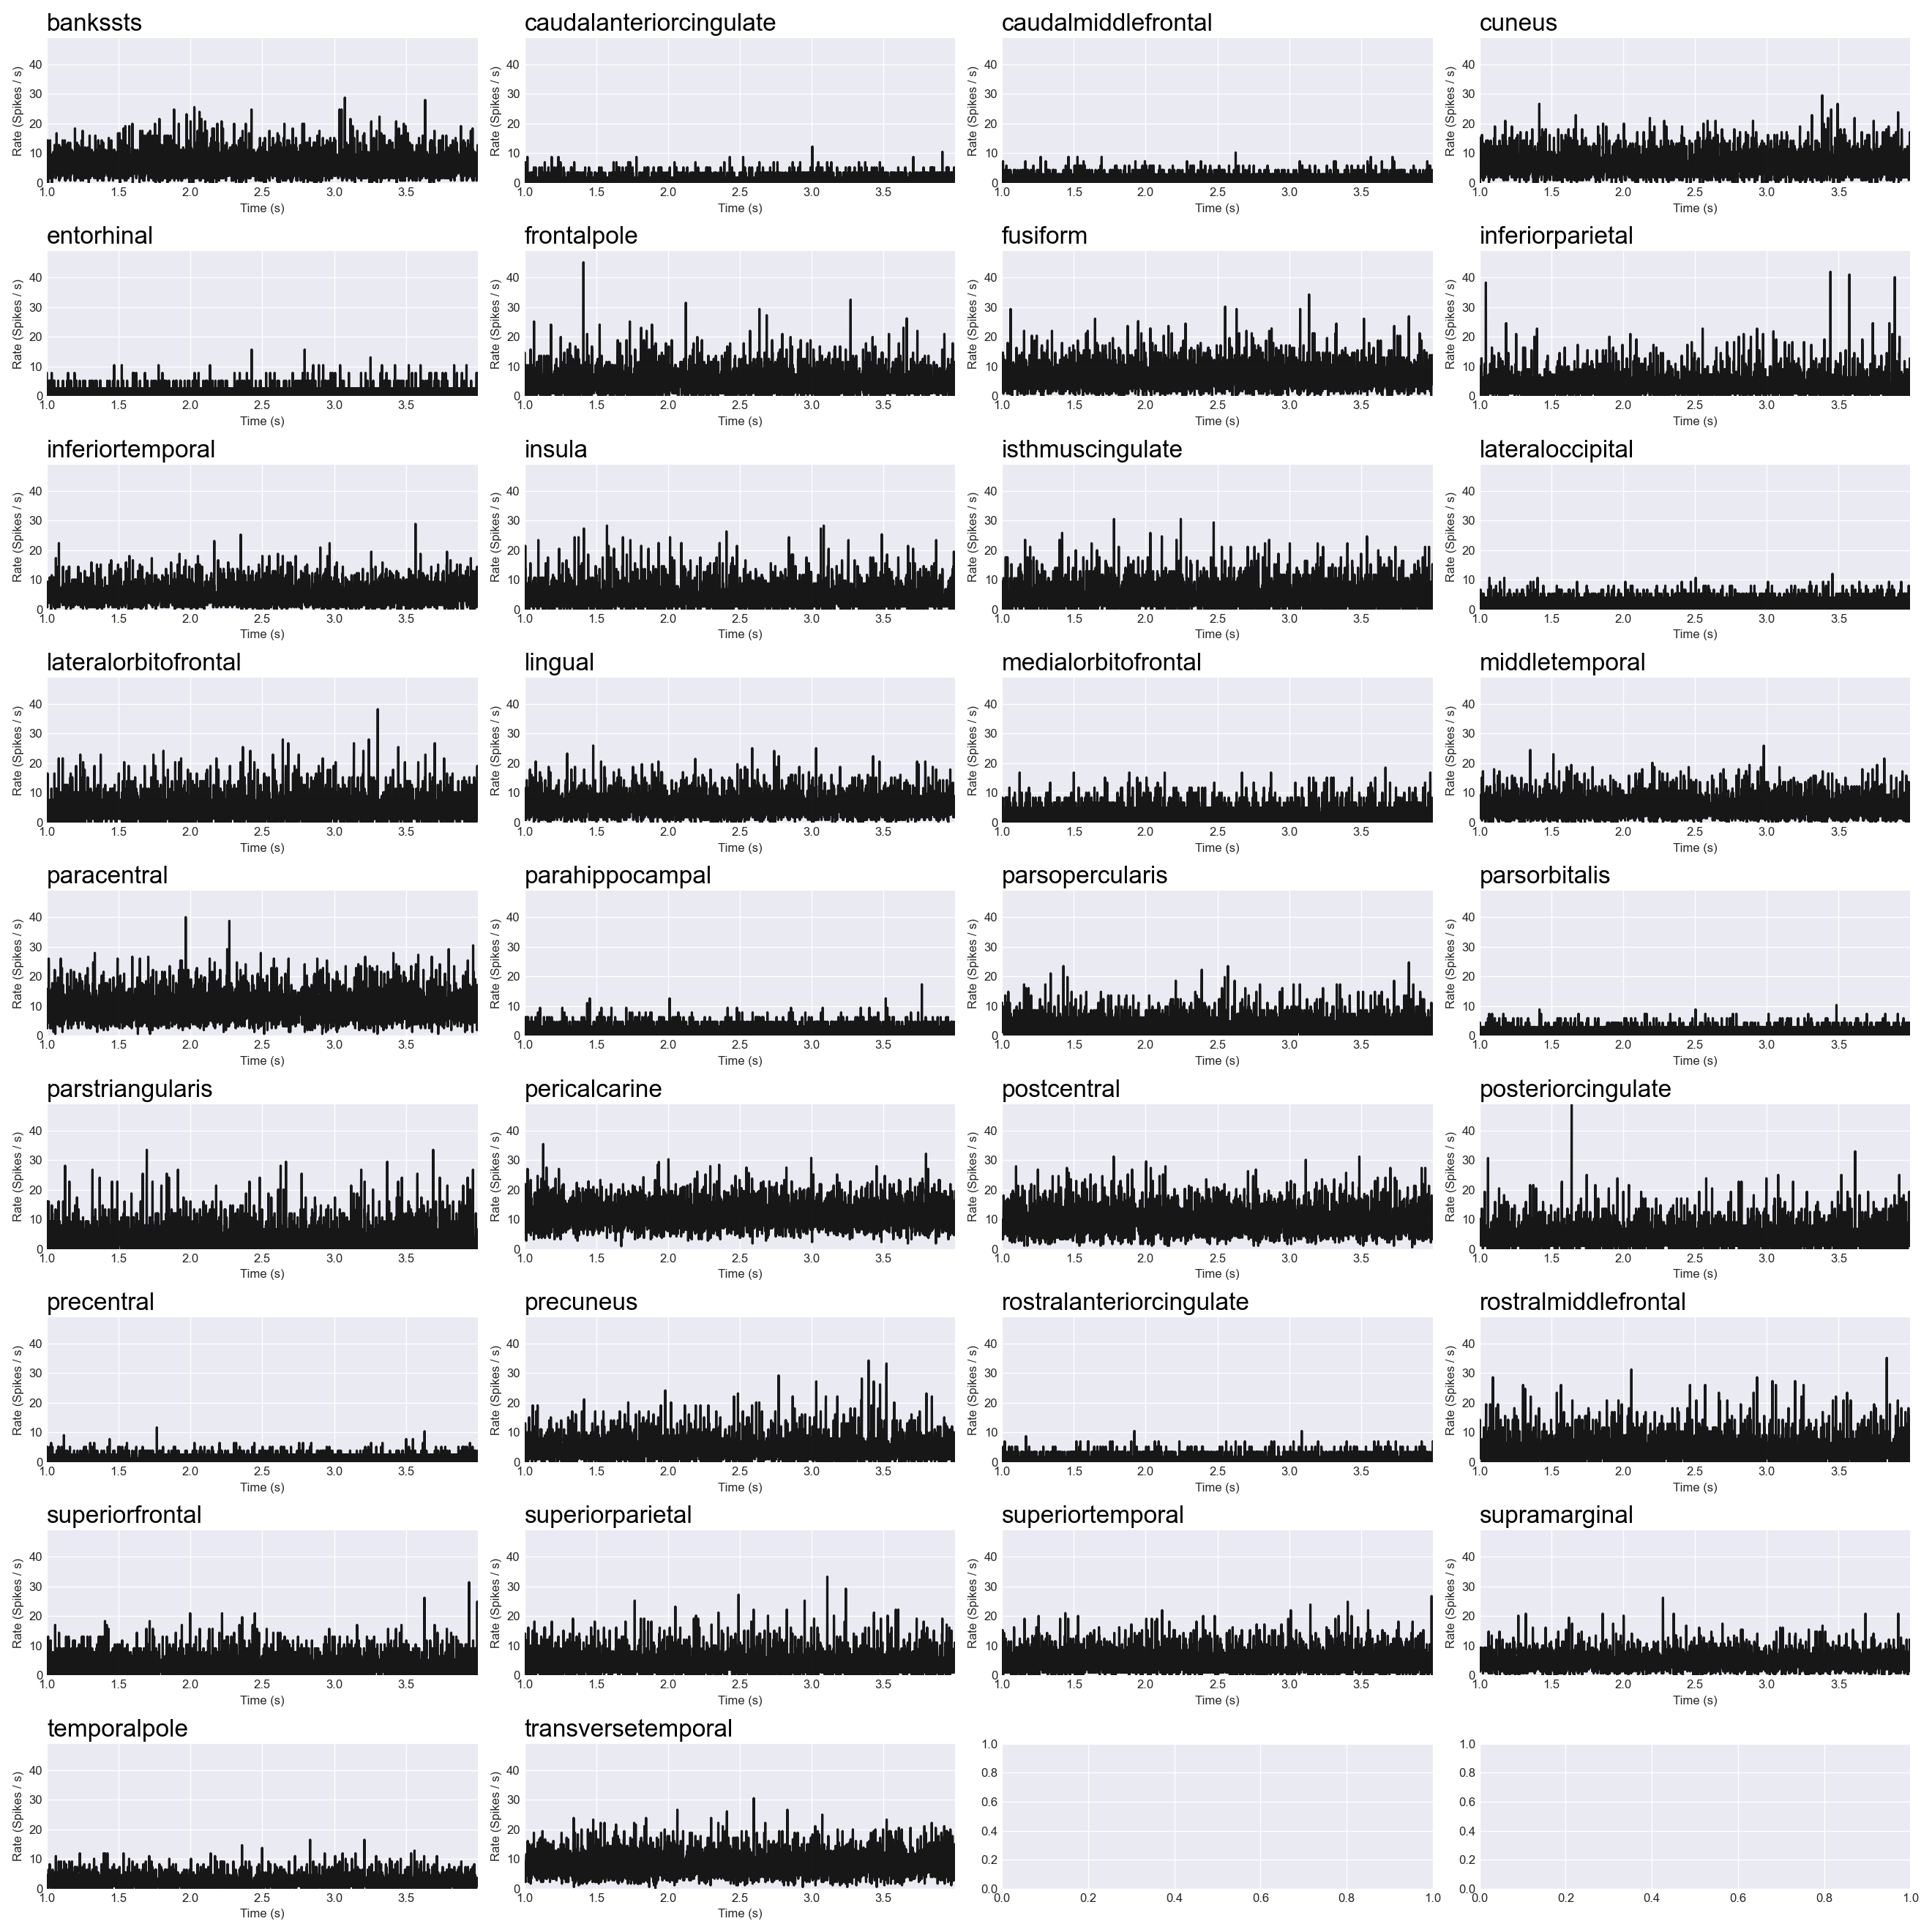

In [9]:
# Figure 4.4 - population rate over time, one panel per area (4.2)
show("tutorial_CN", "spiking_overview_same_y_axis_True.png", width=980)

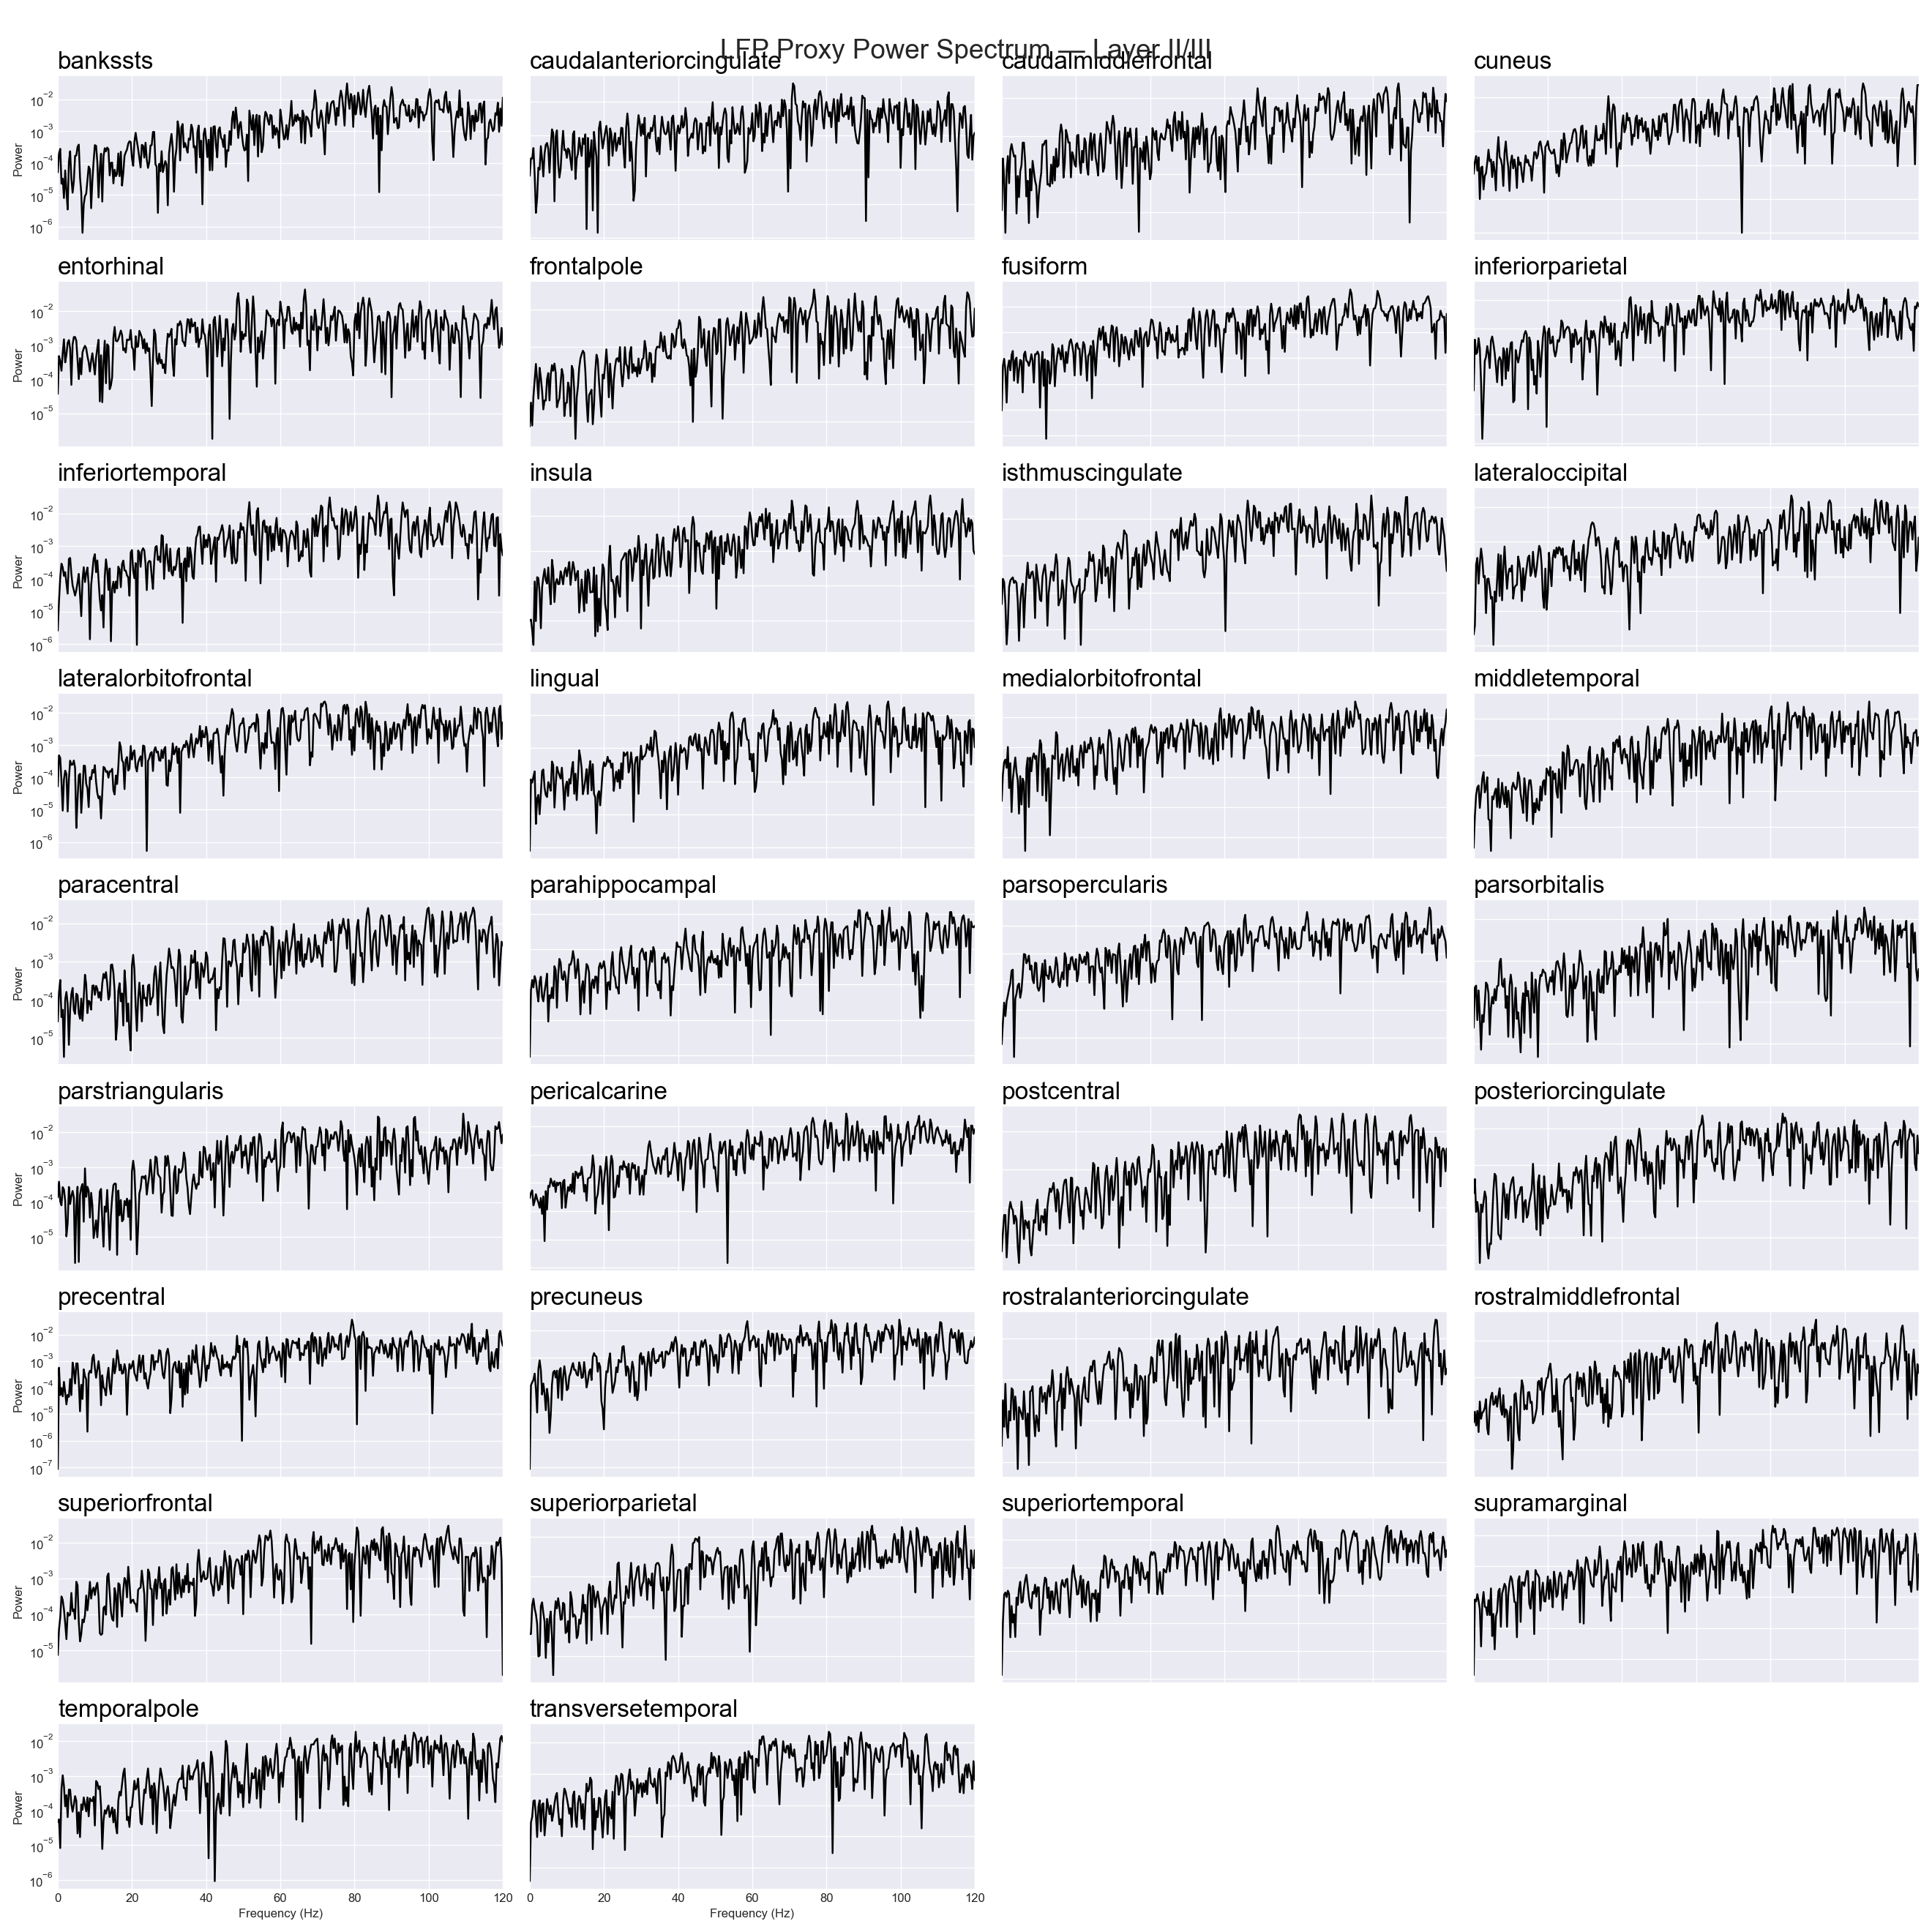

In [10]:
# Figure 4.5 - power spectra of the layer II/III LFP proxy, one panel per area (4.4)
show("tutorial_CN", "lfp_proxy_psd_layer_II_III.png", width=980)

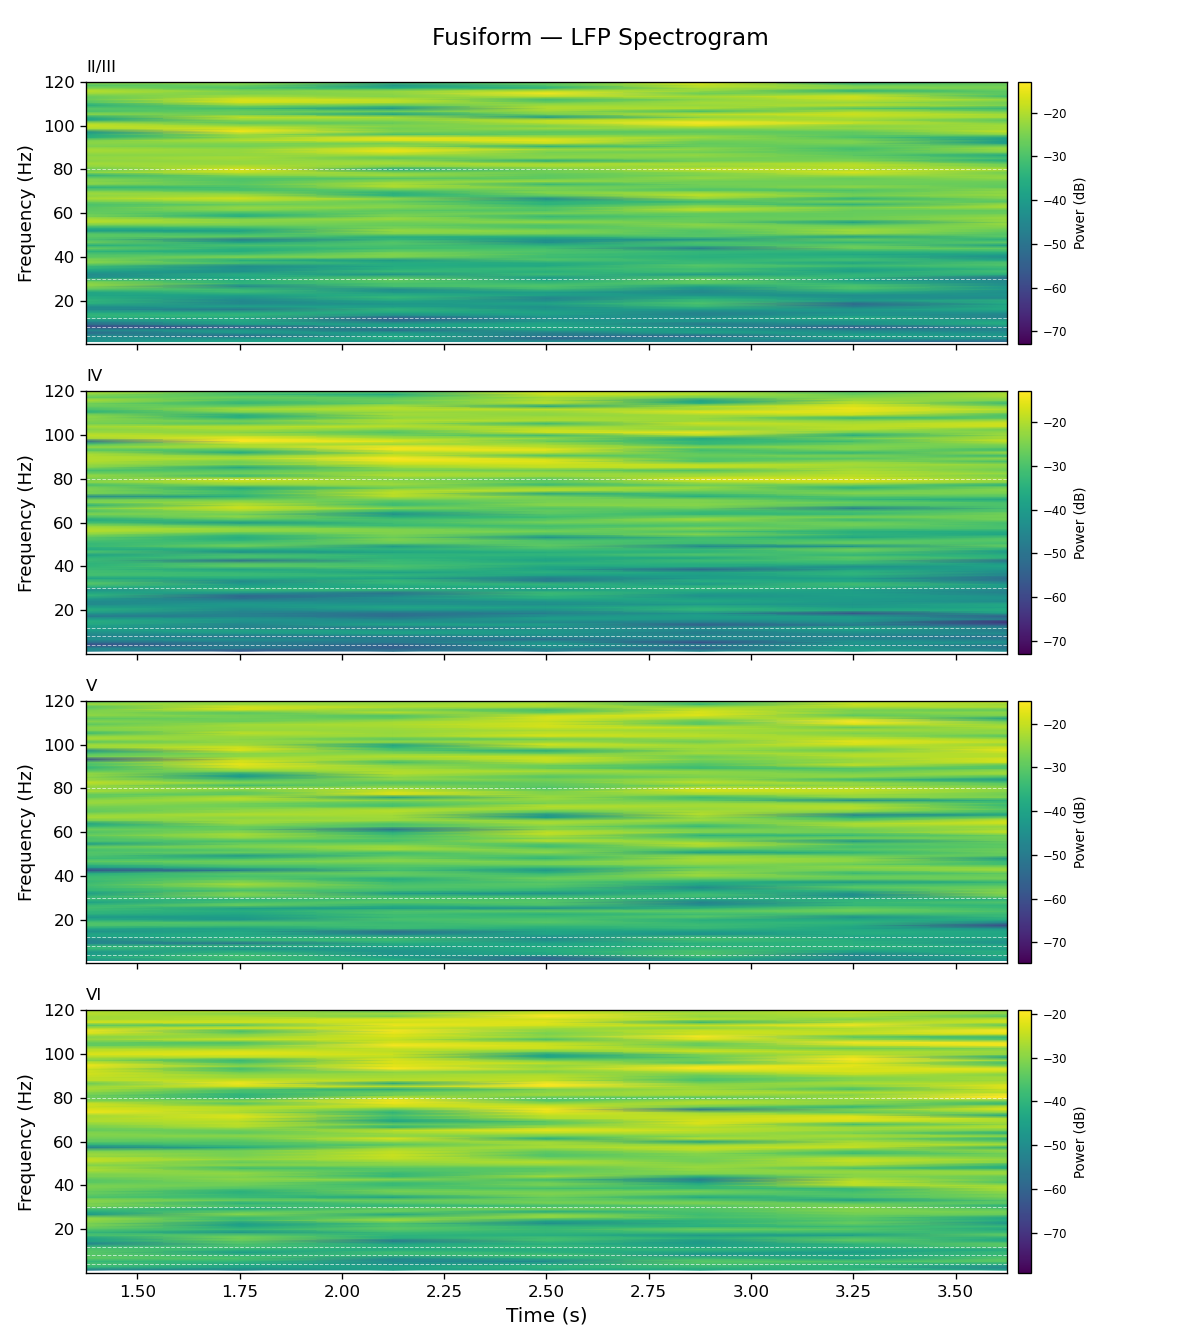

In [11]:
# Figure 4.6 - spectrogram of one area, one panel per layer (4.4)
show("tutorial_CN", "spectrogram/lfp_spectrogram_fusiform.png", width=820)

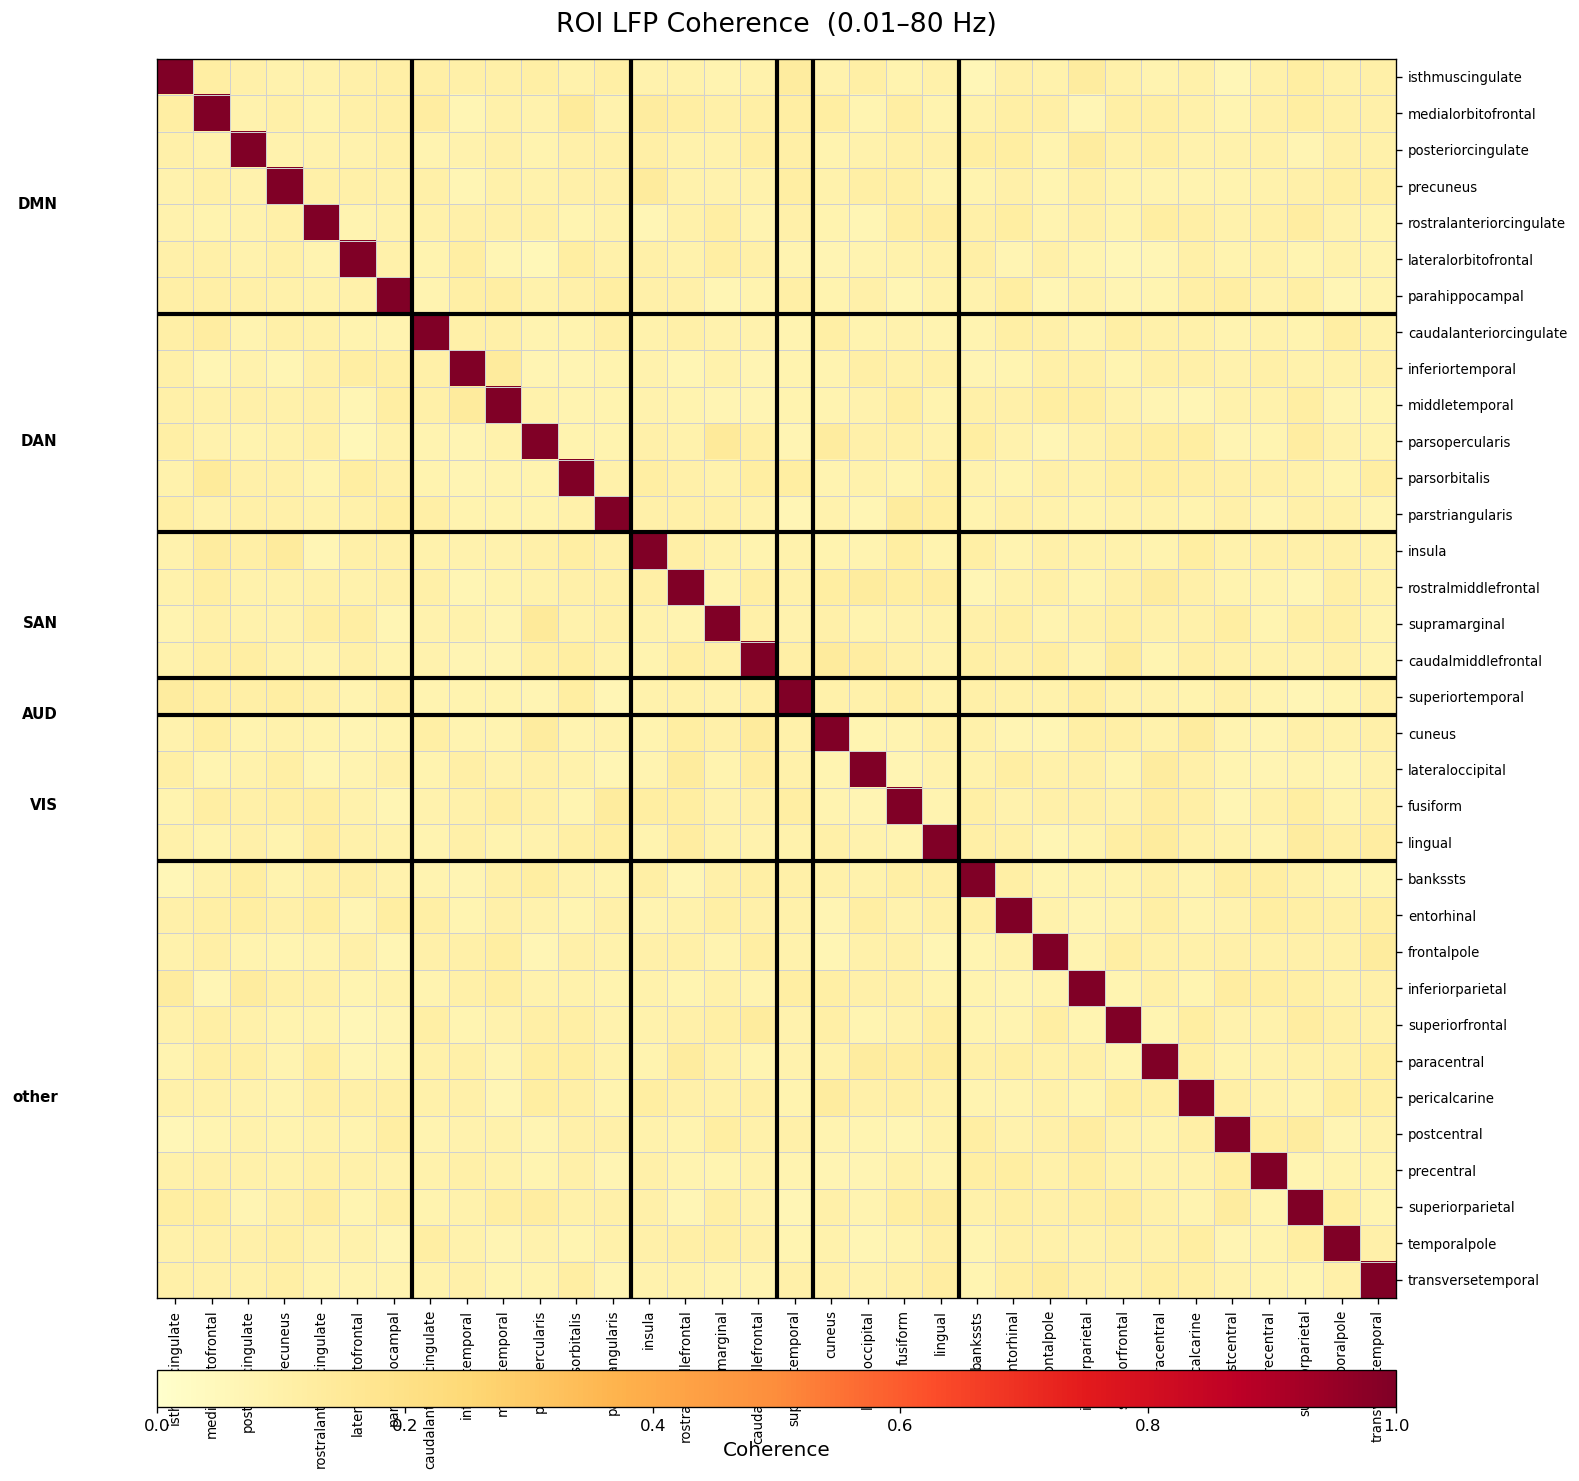

In [12]:
# Figure 4.7 - coherence between the areas' LFP proxies (4.4)
show("tutorial_CN", "lfp_area_coherence.png", width=780)

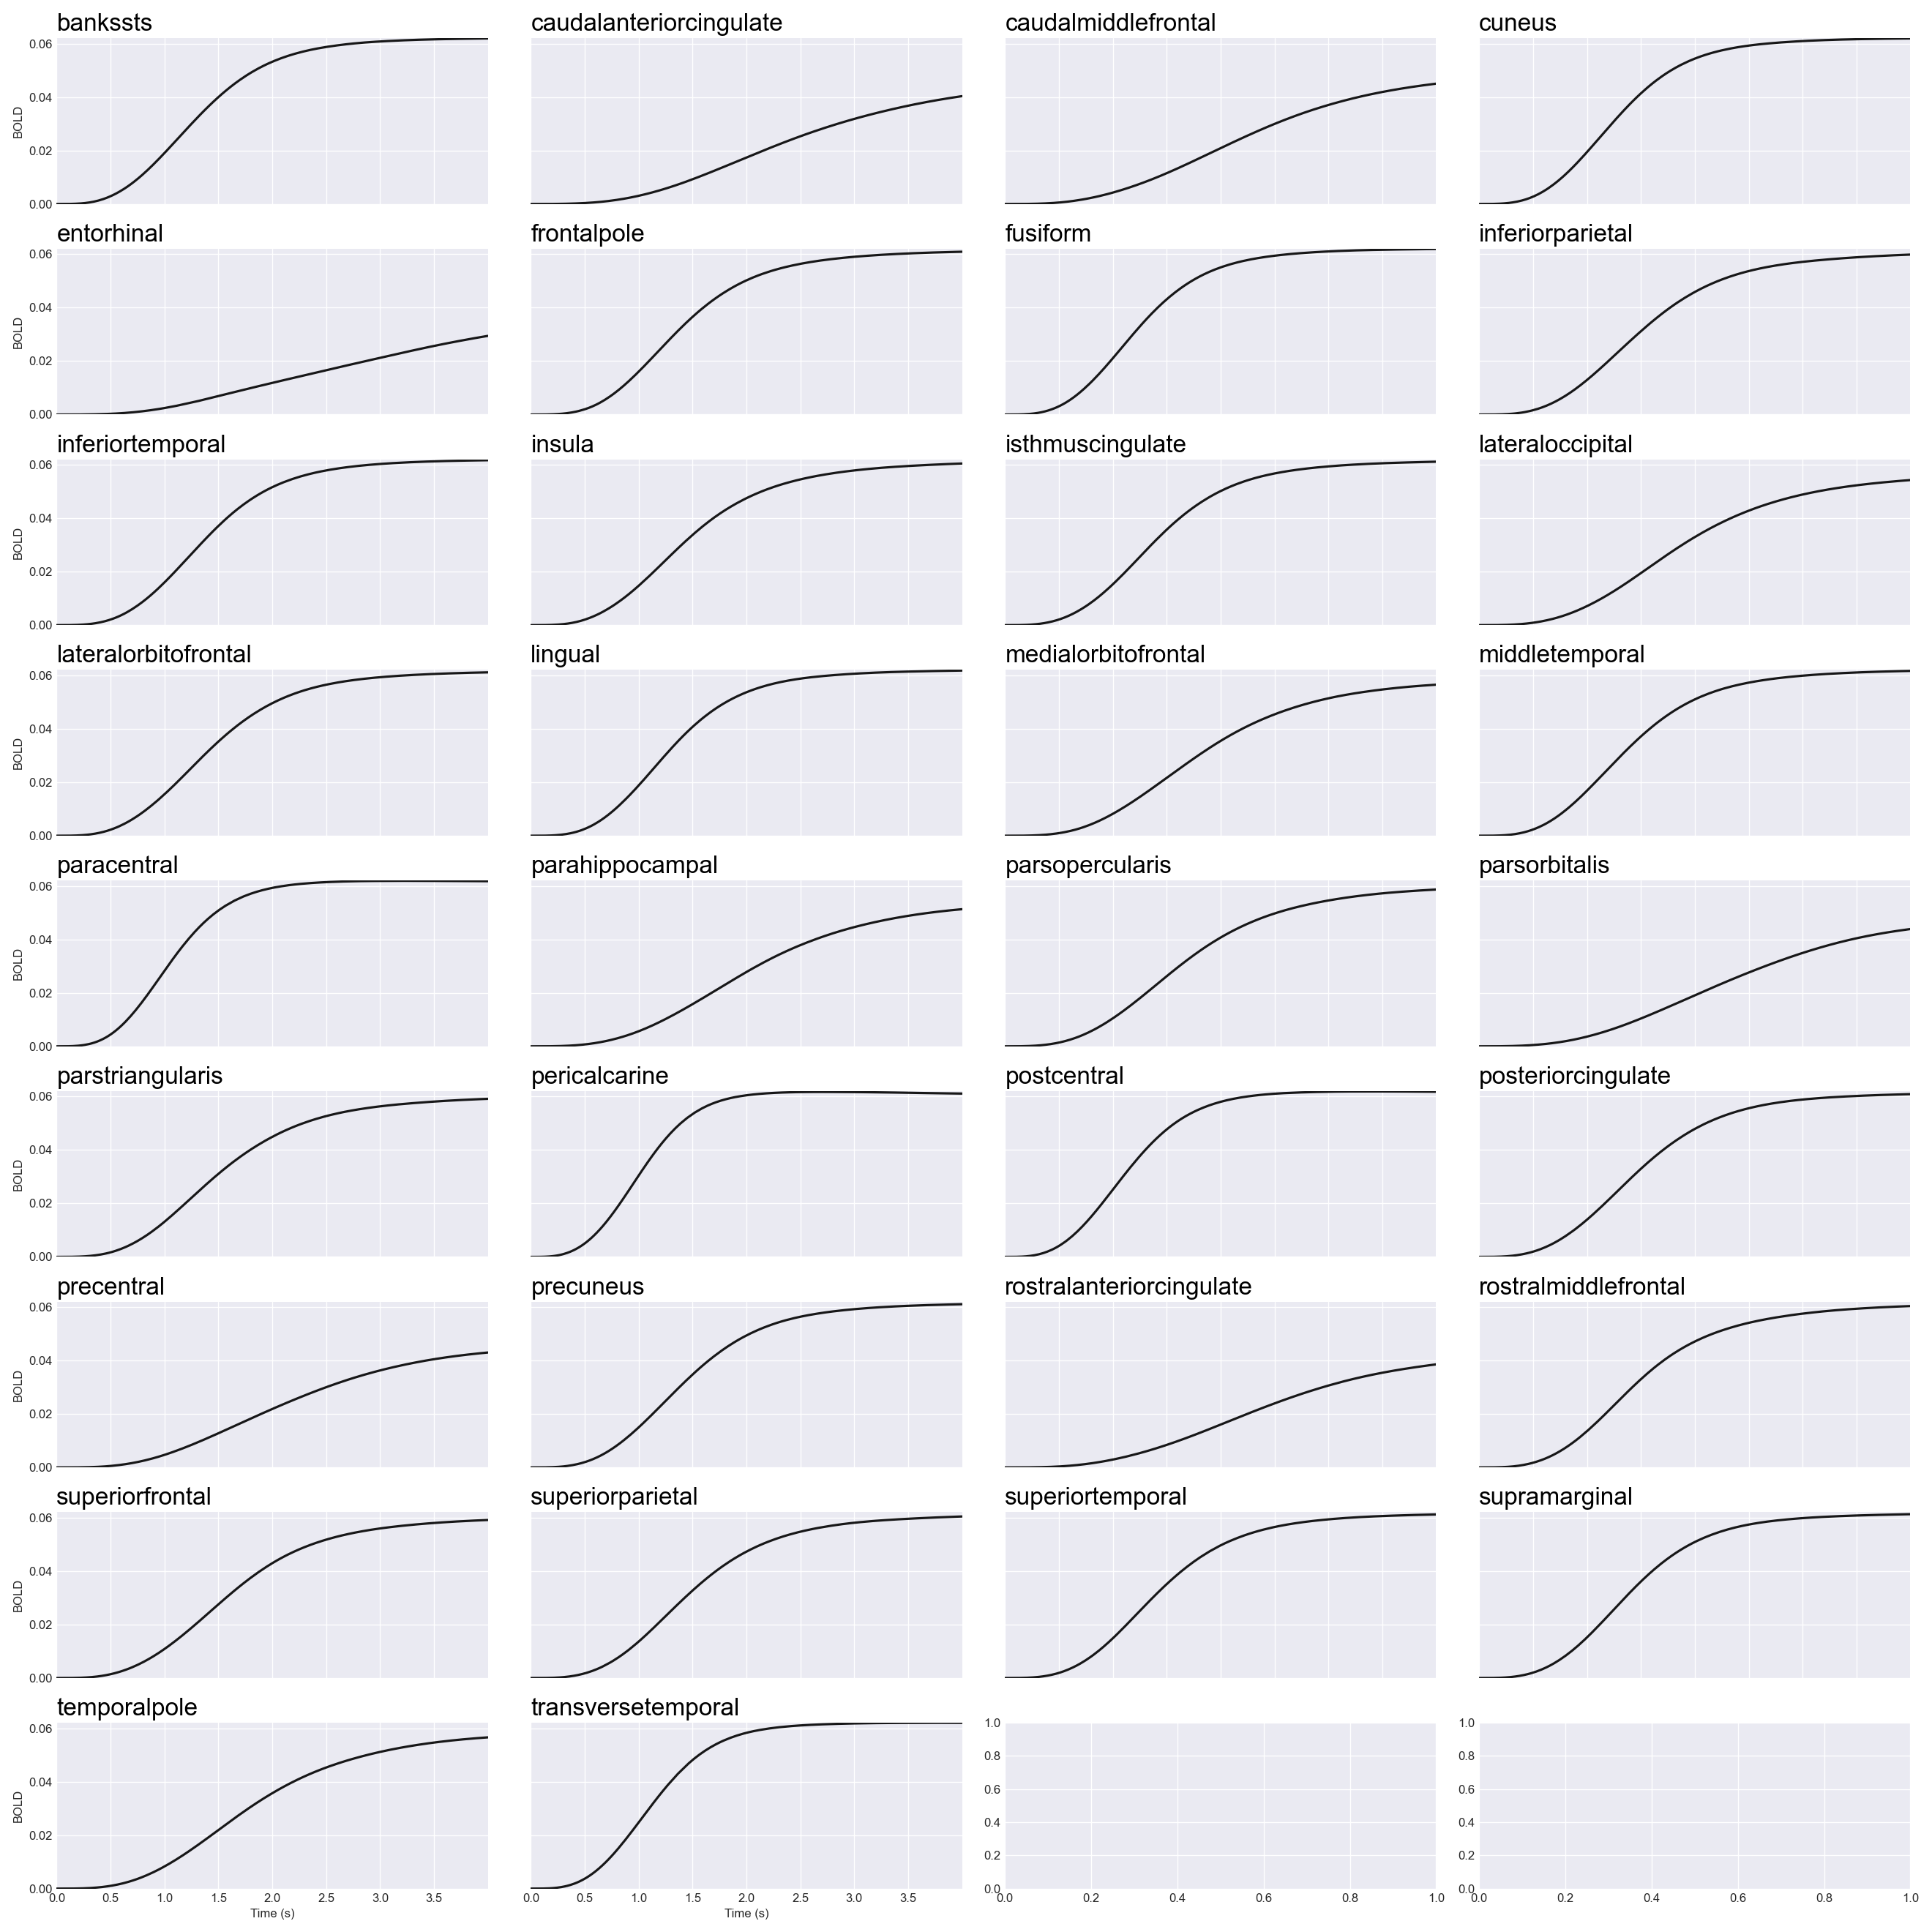

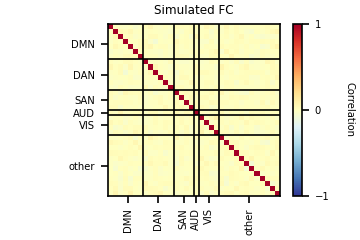

In [13]:
# Figure 4.8 - BOLD signal per area, and the FC matrix of the synaptic input currents (4.5)
show("tutorial_CN", "bold_overview.png", width=980)
show("tutorial_CN", "simulated_fc.png", width=560)

In [14]:
# Figure 4.9 - two of the data files (4.6)
lfp = load_result("tutorial_CN", "lfp_proxy_kernel.pkl")
print(f"LFP proxy : {lfp.shape[0]} (area, layer) signals x {lfp.shape[1]} samples "
      f"at {1000 / (lfp.columns[1] - lfp.columns[0]):.0f} Hz")

busiest = area_mean_rate("tutorial_CN", "E").sort_values(ascending=False)
print("\nmean excitatory rate, five busiest and five quietest areas (Hz):")
print(pd.concat([busiest.head(5), busiest.tail(5)]).round(2).to_string())

LFP proxy : 127 (area, layer) signals x 4000 samples at 1000 Hz

mean excitatory rate, five busiest and five quietest areas (Hz):
area
fusiform                    7.41
middletemporal              6.46
bankssts                    6.28
inferiortemporal            5.93
lateralorbitofrontal        5.16
rostralanteriorcingulate    0.00
lateraloccipital            0.00
parsorbitalis               0.00
caudalanteriorcingulate     0.00
parahippocampal             0.00


---

# Part 5 - Try with Your Own Data

Everything the model knows about a brain arrives through **five slots**. Point a slot at your own
file and every derived quantity - in-degrees, synapse counts, delays, laminar target patterns - is
rebuilt from it. You never edit a connectivity matrix by hand, and you never write inside `model/`.

## 5.1 The five slots

Many more parameters and data files can be replaced; these are the five most common.

| Param/data | Key in dict | Format | Shipped example |
|---|---|---|---|
| **Structural connectivity** | `net_params["predictive_connectomic_params"]["con_path"]` | MATLAB `.mat`, six variables (5.2) | `model/experimental_data/amyloid/amyloid_SC.mat` |
| **Comparison target for FC** | `ana_params["experimental_fc"]` | `.npy`: BOLD series or correlation matrix | `model/experimental_data/amyloid/amyloid_bold.npy` |
| **Neuron parameters** | `net_params["neuron_params_E"]`, `["neuron_params_I"]` | dict of NEST `iaf_psc_exp` keys | `model/src/default_net_params.py` |
| **Cytoarchitecture** | `net_params["cytoarchitecture_params"]["src_path"]`, `["ei_ratio_path"]` | von Economo & Koskinas `.xls`; CSV `layer,ratio` | `model/experimental_data/voneconomokoskinas/`, `fraction_EI/lichtman.csv` |
| **Neuron types / pathology map** | `net_params["neuron_types"][<name>]["ratio_E"]`, `["ratio_I"]` | scalar, dict, or CSV `area,layer,ratio` (5.4, Appendix B) | `model/experimental_data/amyloid/amyloid_ratio.csv` |

All five are ordinary entries in the experiment file, next to the parameters of Part 2. Where you put
them decides which hash changes: a changed `net_params` gives a new network hash, a changed
`ana_params` only a new analysis hash - and on the cluster, which stages re-run (Part 6).


## 5.2 Structural connectivity (`.mat`)

A connectome reconstructed from structural MRI and diffusion-MRI tractography, stored
with the six variables of the group-average HCP file:

| Variable | Shape | Meaning |
|---|---|---|
| `DK_Names` | 34 x 1 cell of strings | area names; the model keeps the text after the last `-`, so `ctx-lh-bankssts` becomes `bankssts` |
| `C_R`, `C_L` | 34 x 34 double | streamline counts between areas, right and left hemisphere |
| `LowResDK_EstimatedDist_RHem`, `..._LHem` | 34 x 34 double | fibre lengths in **mm** |
| `Dist` | 34 x 34 double | Euclidean distances in mm |

- The model reads **`C_R`** and **`LowResDK_EstimatedDist_RHem`** - the *right*-hemisphere variables -
  even though the area names carry a `ctx-lh-` prefix. Put the hemisphere you mean in those two.
- `DK_Names` must match the atlas list **exactly and in the same order**.
  `data_preprocessing/connectivity.py` asserts it against `DKAtlas_VolumeAndNames.mat`, so a
  re-ordered or renamed list aborts stage 1 rather than producing a scrambled network.
- Streamline counts are used **row-relative**: each row is divided by its own sum, scaled by
  `1 - FLN`, and the diagonal is then overwritten with `FLN = 0.86`. The absolute scale of your
  matrix is therefore irrelevant - but a row of zeros is an area with no outgoing projection, and
  there is nothing to normalise.

Fibre lengths become the inter-area delays, so they must be lengths in mm - not voxels, not seconds.


## 5.3 Comparison target (`.npy`)

Either a BOLD time series, `frames x nodes` with an optional third
participant axis, or a square `nodes x nodes` correlation matrix. `nodes` must be **68** (cortex
only: lh `0:34`, rh `34:68`) or **84** (full DK: lh `0:34`, rh `49:83`). The default value is the
sentinel `"rsDATA_7T_DKparcel.npy"`, which selects the group-averaged Senden 7T reference; any other
string is read as a path to your file.

## 5.4 Neuron parameters

The `iaf_psc_exp` keys, in NEST's units: `E_L`, `V_th`, `V_reset` (mV),
`C_m` (pF), `tau_m`, `tau_syn_ex`, `tau_syn_in`, `t_ref` (ms). `neuron_param_dist_E` / `_I` add
lognormal spread per parameter (`rel_sd: 0` switches it off; the values fitted to the Allen GLIF
recordings sit in the comments of `default_net_params.py`). Pathological or other custom neuron
types go into `neuron_types`, a dict keyed by a name of your choice. Each type takes `ratio_E` /
`ratio_I` (its fraction of every population) and optionally `neuron_model_E`, `neuron_params_E`,
`neuron_param_dist_E` and the `_I` versions; parameters left out are inherited from the healthy
neuron, so `{"neuron_params_E": {"V_th": -50.0}}` changes only the threshold. Several types may
coexist as long as their fractions sum to at most 1.

**`V_th - E_L` is the working point**, 25 mV by default, and the drive `eta_ext` is expressed in
units of it. Change either potential and you have moved the operating point of the entire network;
recalibrate before reading anything except the rates (5.6).

## 5.5 Check a file before you run it

Stage 1 needs about a minute to reach the assertion that rejects a malformed connectome.
`check_data()` reads the contract above off the file in a second and names what is wrong - it
dispatches on the suffix, so the same call works for all three file kinds.

The cell below is an example and is commented out: to use it, uncomment it and replace the file
names with your own data files.

In [15]:
# Example - uncomment, and replace the file names with your own data files.
# for name in ["amyloid_SC.mat", "amyloid_bold.npy"]:
#     check_data(MODEL_ROOT / "experimental_data" / "amyloid" / name)
#     print()

When the data changes, three things need re-checking, in this order:

1. **The working point.** Your connectome has its own in-degree distribution, and your neurons their
   own distance to threshold, so the rates move. Run the check of Part 4.1 first: excitatory 3-5 Hz,
   inhibitory 5-15 Hz. Outside that band, recalibrate `eta_ext` (5.6) before reading anything
   downstream of the rates.
2. **The hashes, and the run's name.** A new `con_path` or neuron parameter changes `net_params`, so
   the network hash changes. A run's directory is named after its experiment file, and running the
   same name again replaces it - so make the change in a *copy* with a new name (B.8 shows one). Both runs
   then sit side by side in `results/`, which is what makes the before/after comparison honest.
3. **The comparison.** Simulated functional connectivity may only be held against a reference in the
   same parcellation, and ideally from the same person. Swapping in one person's connectome while
   leaving `experimental_fc` at its default compares that person's model against the average of 19
   other people.

## 5.6 Re-calibrating the working point: `eta_ext` and the full-scale rates

Two numbers in the experiment file set the working point of a downscaled network, and each depends
on the other:

- **`input_params["eta_ext"]`**, the external drive in units of the distance to threshold. It is the
  dial: too low and the network falls silent, too high and it runs away.
- **`fullscale_rates`**, the population rates of the *full-scale* version of the same experiment.
  Downscaling keeps only part of the mean recurrent input; the rest is supplied as a DC current
  computed from these rates (Appendix A). They belong to one configuration - its drive, weights,
  connectome and neurons - and a file left over from another configuration gives the wrong DC current.

Change the data (5.1-5.4), the scale or the long-range gains, and both have to be redone, with one
tool each:

| Tool | Notebook | Does | Cost here |
|---|---|---|---|
| `tools/eta_ext_search.py` | `eta_search(experiment, etas)` | builds the experiment as its file defines it, changing only `eta_ext`, simulates it for every candidate value and reports the mean E / I rates | ~1 min + ~4 min per value |
| `tools/fullscale_rates.py` | `fullscale_rates(experiment, eta=...)` | iterates rates -> DC current -> simulation -> rates until they agree | ~4 min per iteration, 40 iterations (~3 h) |

Costs measured at the default size (`N_scaling` = 0.01) with two calibrations sharing a 16-core laptop.

**The procedure**, for the *healthy* experiment:

1. **Scan** a few values of `eta_ext` with the experiment's current rates file and pick the one whose
   mean rates fall in the target bands (E 3-5 Hz, I 5-15 Hz). If the rates file belongs to another
   configuration the scan is only a first guess - which is what step 2 fixes.
2. **Generate the full-scale rates** at the chosen value. The printed table shows one line per
   iteration; the last two columns, the mean change per step, must level off (at roughly
   0.3 Hz for E and 0.1 Hz for I at this size - finite-size noise). The default of 10 iterations of
   the command-line tool stops well short of that; use 40.
3. **Write both into the experiment file** - `"input_params": {"eta_ext": ...}` and
   `"fullscale_rates"` pointing at the new file (or copy it to `experiments/fullscale_rates/`) - and
   run it with `run_all`. Check the rates as in 4.1.
4. If they left the bands, repeat steps 1-3 once, now with the new rates file.

Both tools read the experiment file themselves - every `net_params` entry (scale, gains, connectome,
neurons, cytoarchitecture), its `fullscale_rates` and its `master_seed` - so a copy with your own data
is calibrated exactly as it will run. Only an experiment with `neuron_types` is refused: it keeps the
drive of its healthy control.

Both tools write their results to `results/calibration/<experiment>/`, never into `experiments/`, so a
calibration run cannot overwrite the rates an experiment ships with. On the command line (flags such
as `--n-scaling` or `--seeds` override single values of the experiment):

```bash
python tools/eta_ext_search.py --experiment experiments/tutorial_CN.py \
    --method scan --eta-list 4.0 4.5 5.0 5.5 \
    --outdir results/calibration/tutorial_CN/eta_search
python tools/fullscale_rates.py experiments/tutorial_CN.py --eta 5.0 --iters 40 \
    --out results/calibration/tutorial_CN/fullscale_rates_eta5.pkl
```


In [16]:
# Re-calibration takes hours at the default size, so it is off by default.
RUN_CALIBRATION = False
EXPERIMENT = "tutorial_CN"     # the healthy experiment to calibrate - put your copy's name here

# Step 1: mean rates of the experiment for a few values of eta_ext,
# simulated with its current full-scale rates file.
if RUN_CALIBRATION:
    scan = eta_search(EXPERIMENT, etas=[4.0, 4.5, 5.0, 5.5])
    display(scan.round(3))
else:
    print("Calibration skipped - set RUN_CALIBRATION = True to run it (~3 h).")


Calibration skipped - set RUN_CALIBRATION = True to run it (~3 h).


In [17]:
# Step 2: full-scale rates at the chosen drive (~3 h for 40 iterations).
ETA = 5.0          # the value picked from the scan above

if RUN_CALIBRATION:
    fs_rates, fs_path = fullscale_rates(EXPERIMENT, eta=ETA, iters=40)
    # Step 3: what goes into the experiment file
    print(f'\n    "input_params": {{"eta_ext": {ETA}}},')
    print(f'    "fullscale_rates": "{fs_path}",')


# Part 6 - Beyond the Laptop

The downscaled model is a development instrument. Quantitative results - functional connectivity
above all, because it is a collective property - need the full-scale network.

## 6.1 The same three stages, wired by Snakemake

On a cluster you do not call the three commands by hand, and you do not want to repeat a stage
that took hours. This is the one place in the tutorial where results
are **reused**:

```snakemake
import os
import sys

# Single-run workflow: network creation -> simulation -> analysis, one random
# seed per experiment. Every experiment file in experiments/ is run; list
# names in EXPERIMENTS by hand to run only some of them.
EXPERIMENTS = [os.path.splitext(f)[0] for f in os.listdir('experiments')
               if f.endswith('.py')]

BASE_PATH = os.getcwd()
THREADS_SIMULATE = 4

rule all:
    input:
        expand('experiments/{experiment}.analysis_hash', experiment=EXPERIMENTS)

rule createNetwork:
    input:
        'experiments/{experiment}.py'
    output:
        'experiments/{experiment}.network_hash'
    threads:
        1
    log:
        'out/log/{experiment}_createNetwork.log'
    shell:
        'python src/snakemake_network.py {input} {output} {log}'

rule simulateNetwork:
    input:
        'experiments/{experiment}.py',
        'experiments/{experiment}.network_hash'
    output:
        'experiments/{experiment}.simulation_hash'
    threads:
        THREADS_SIMULATE
    log:
        'out/log/{experiment}_simulateNetwork.log'
    shell:
        'mpirun python src/snakemake_simulation.py {input} {output} {threads} {log}'

rule analyzeNetwork:
    input:
        'experiments/{experiment}.py',
        'experiments/{experiment}.network_hash',
        'experiments/{experiment}.simulation_hash'
    output:
        'experiments/{experiment}.analysis_hash'
    threads:
        1
    log:
        'out/log/{experiment}_analyzeNetwork.log'
    shell:
        'python src/snakemake_analysis.py {input} {output} {BASE_PATH} {log}'

```

NEST distributes connections across MPI ranks, so what matters is the **aggregate** RAM, plus 20-30%
headroom for the spike-communication buffers allocated during `Prepare`.



## 6.2 Full-scale results

Everything above ran on a laptop with a fraction of the neurons. The runs below are the full model:
one hemisphere with **3.47 million neurons and 42.8 billion synapses**, 10 s of biological time,
computed on our server with the Snakemake workflow of 6.1. They are three hemispheres of three
participants of the THU glioma cohort, with identical parameters:

| | |
|---|---|
| Hemispheres | `sub007_L`, `sub016_L`, `sub011_R` - left, left and right hemisphere of three participants |
| Connectome | each person's own (`sub007_L.mat`, `sub016_L.mat`, `sub011_R.mat`) - the only difference between the runs |
| Scale | `N_scaling` = `K_scaling` = 1: no downscaling, no DC compensation |
| Drive | the repository default, `eta_ext` = 1.1 |
| Long-range gains | `cc_scalingEtoE` / `cc_scalingEtoI` = 2.5 / 5.0, the repository default |
| Simulated time | 10 s, `master_seed` = 2903 |

- `sub007_L` changes state once, from active to quiet - the clearest example of what a full-scale
  network does and a downscaled one cannot (4.3). It is shown first;
- `sub016_L` changes state 16 times, back and forth;
- `sub011_R` stays in the active state, but pauses in it for up to 100 ms about ten times.

The two that change state are also the cohort's best and worst fit of simulated to empirical
functional connectivity, which is no coincidence (end of this section).

### `sub007_L` - one change of state

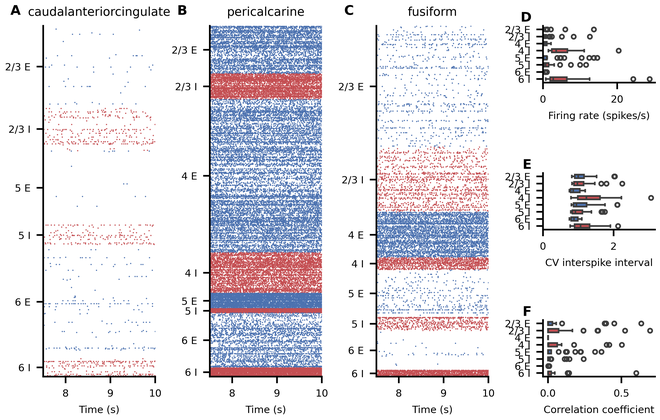

In [18]:
# Figure 6.1 - the server's own summary figure (the checklist of 4.1)
show_figure("fullscale/sub007_L/server_spike_statistics.png", width=660)

Figure 6.1 is what the server's analysis stage drew, with its parameters fixed: rasters of the last
2.5 s (7.5-10 s) and the spike statistics of the run. Judged by it alone, the network passes the
checklist of 4.1 - sparse, irregular, decorrelated firing - at a low mean rate (E 1.0 Hz, I 3.4 Hz).
Resolved in time, the run tells a different story.

The run is in two states, split at 4.4 s:

- **until 4.4 s** a group of areas - postcentral, supramarginal, pericalcarine, superior parietal,
  precentral, insula - fires in synchronous bursts that recur every 0.5-0.8 s, while frontal and
  cingulate areas stay below 1 spike/s. Mean rates: E 2.0 Hz, I 6.2 Hz; 12 populations silent, the
  fastest at 63 Hz;
- **after 4.4 s** the whole hemisphere fires at a low, steady rate: E 0.4 Hz, I 1.6 Hz, no population
  silent, none faster than 8 Hz.

The means of Figure 6.1 (E 1.0 Hz, I 3.4 Hz) average the two states. The first second, in which the
network settles from its initial conditions, is left out of every statistic.

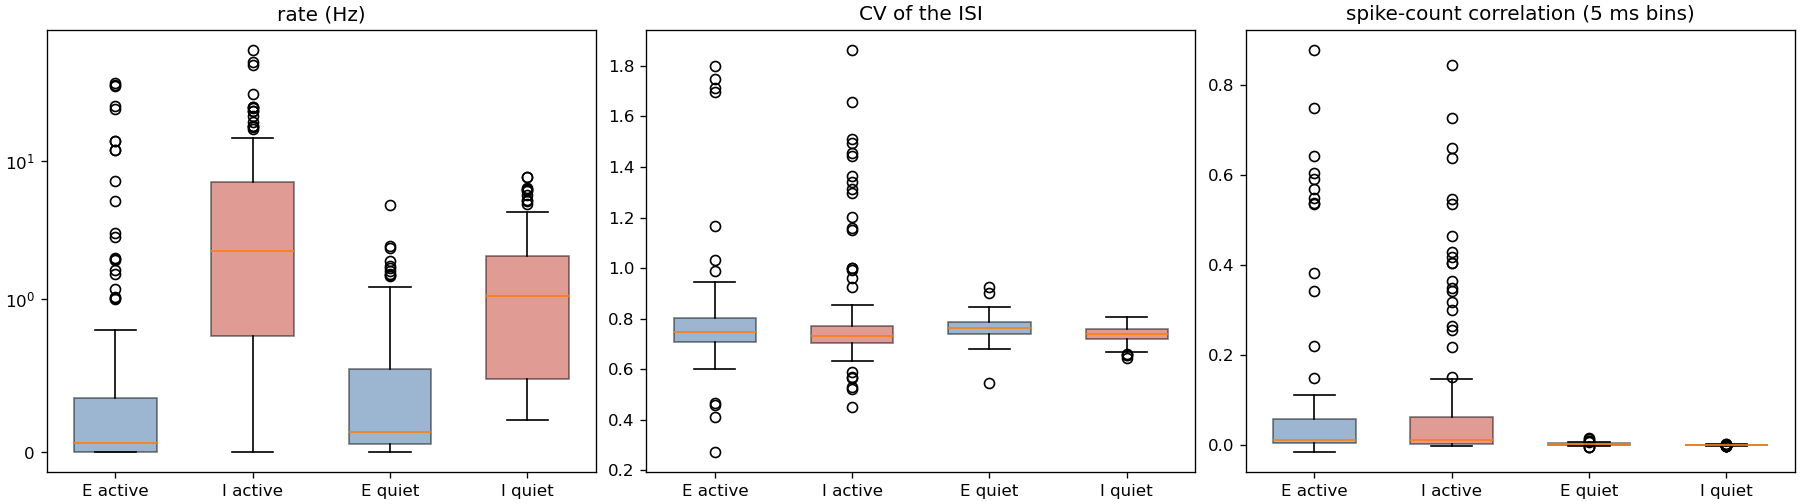

In [19]:
# Figure 6.2 - rate, irregularity and synchrony in each state, sub007_L
show_figure("fullscale/sub007_L/state_statistics.png", width=980)

Figure 6.2 computes the three numbers of the checklist of 4.1 - rate, irregularity, synchrony - for
every population, in each state separately. The states are labelled **active** (before the switch)
and **quiet** (after it), the names used for them from here on.

The medians barely move - most populations are quiet in both states - and the difference sits in the
tails:

- **rate**: before the switch 36 populations fire faster than 10 spikes/s, up to about 60; after,
  none is above 8;
- **irregularity**: the CV is about 0.75 in both states, but before the switch 15 populations are
  above 1.2 - bursts; after, none;
- **synchrony**: before the switch 39 populations have a spike-count correlation above 0.1, up to
  about 0.9 - neurons firing in lockstep; after, none is above 0.02.

The two states are the two ends of what recordings call **cortical state**: *synchronized*, with
population bursts separated by silence, and *desynchronized*, asynchronous and irregular (Harris &
Thiele 2011). The model produces both from the same parameters, and the second one passes the
checklist of 4.1 on irregularity and synchrony, at rates below the target bands (E 0.4 Hz, I 1.6 Hz).
A raster is a window and a mean is an average; the time course is what tells you whether they describe
one network state or two.

### `sub016_L` - back and forth

The same parameters on another person's connectome, with the two states defined explicitly: a
stretch counts as **quiet** when the mean rate over all areas stays below 0.6 spikes/s for at least
200 ms - in the quiet state it sits at about 0.45 spikes/s, in every hemisphere of the cohort - and
everything else as **active**. The quiet stretches are shaded in Figure 6.3, and the statistics of each
state leave out the first 100 ms after every change into it. For `sub007_L` this definition gives the
split used above. The time-resolved figures start at 0.5 s; the first second is shown but left out of
every statistic.

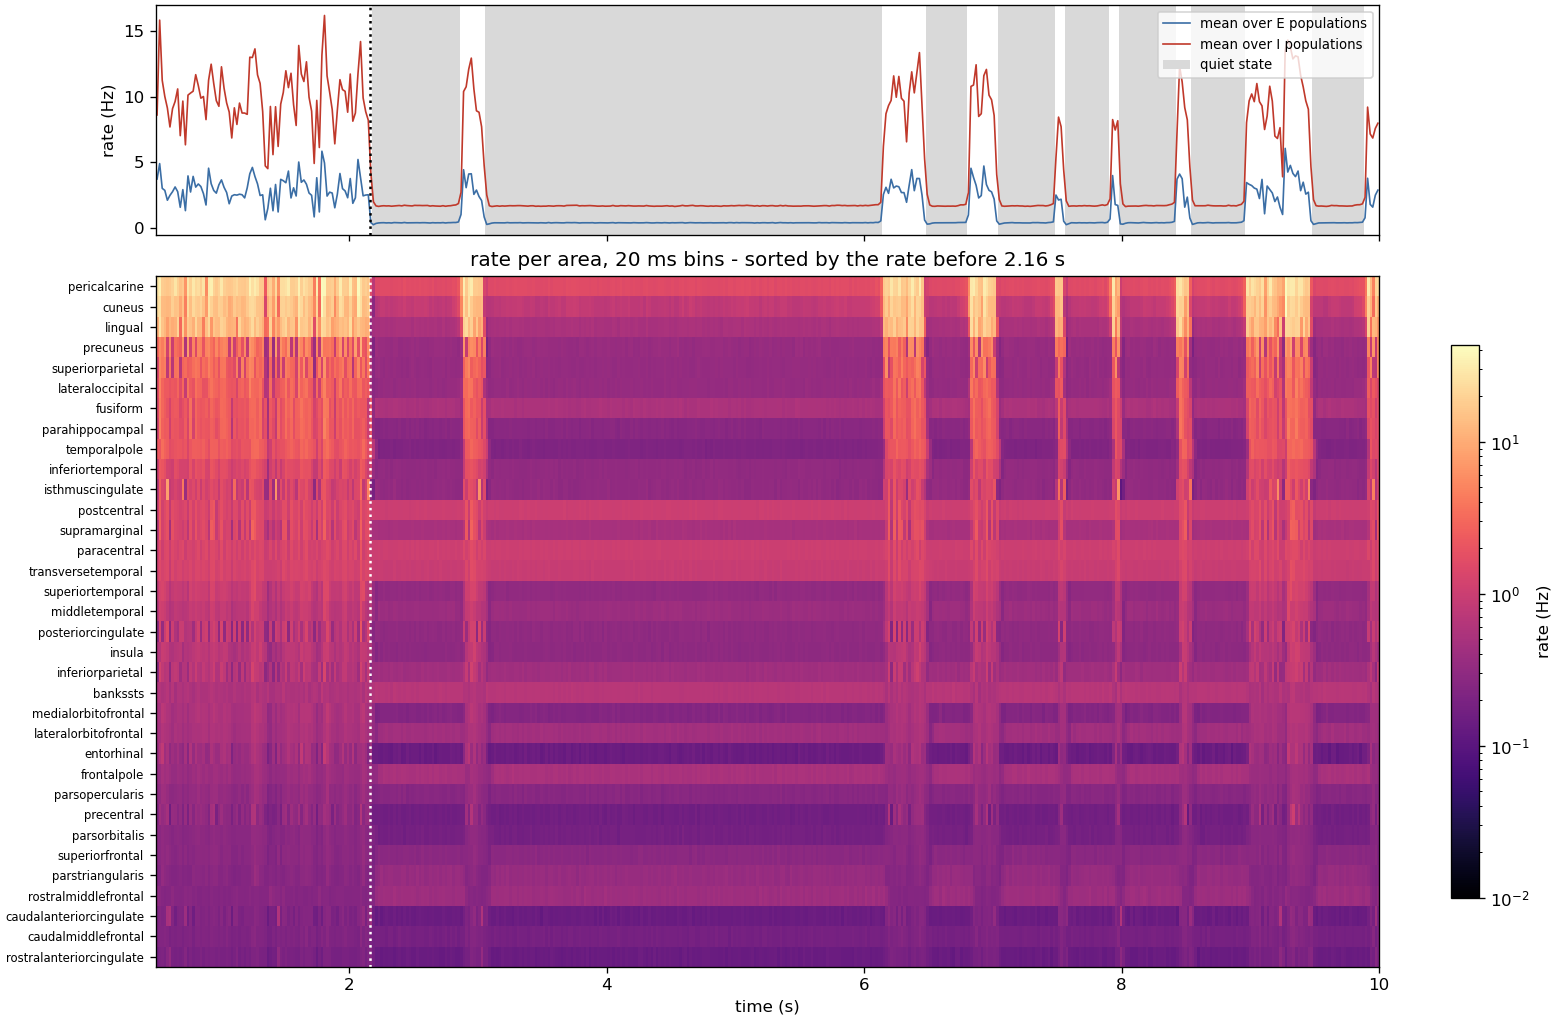

In [20]:
# Figure 6.3 - rate over time, sub016_L: the whole hemisphere (top, quiet state shaded) and every area (bottom)
show_figure("fullscale/sub016_L/state_switch_areas.png", width=980)

Figure 6.3: the run starts in the active state, with a group of areas like that of `sub007_L` but
centred further back - pericalcarine, cuneus and lingual (visual cortex), then precuneus, superior
parietal, lateral occipital and fusiform. At 2.16 s it switches to the quiet state, and it does not
stay there: it returns to the active state eight times, for 80-520 ms each (the last return is cut off
by the end of the run), and falls back each time - 16 changes of state, 68% of the time quiet, quiet
stretches of 0.3-3.1 s. The two states are those of `sub007_L`:

- **active**: E 2.8 Hz, I 9.6 Hz; 21 populations silent, the fastest at 148 Hz;
- **quiet**: E 0.37 Hz, I 1.7 Hz; no population silent, none faster than 8.2 Hz.

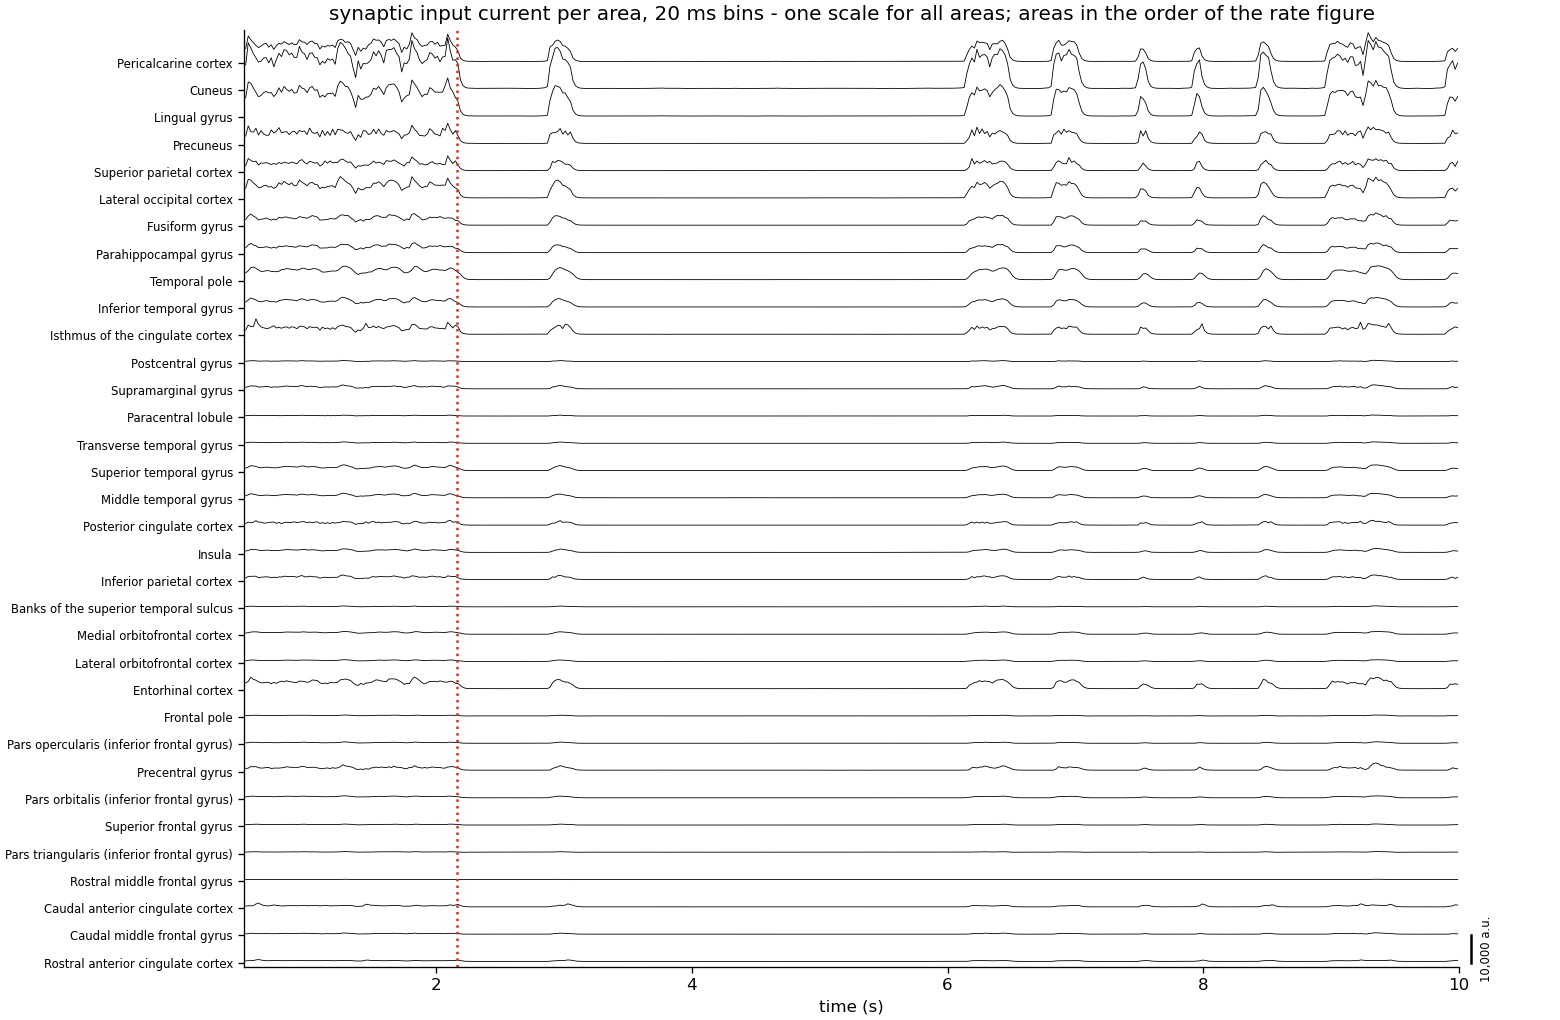

In [21]:
# Figure 6.4 - synaptic input current per area, sub016_L: one trace per area
show_figure("fullscale/sub016_L/synaptic_currents.png", width=980)

Figure 6.4 shows the same run as the **synaptic input current** of each area, one trace per area
like the leads of an ECG, in the order of Figure 6.3. It is the recurrent input the area's neurons
receive - excitatory and inhibitory, summed in magnitude, averaged over the area - and the signal the
functional connectivity at the end of this section is computed from. The traces are not normalised:
all areas, in all three runs, share one scale (the bar at the bottom right, in the arbitrary units of
the analysis output), so large deflections run into the rows above. Here the largest are in visual
cortex -
cuneus (up to about 19,000), lingual, pericalcarine, lateral occipital, precuneus. Every return to
the active state raises the current of these areas, and of the temporal and parahippocampal areas
with them, at once; every return to the quiet state drops them to the same flat baseline. The frontal
and sensorimotor areas barely move - postcentral included, which carried one of the largest currents
in `sub007_L`.

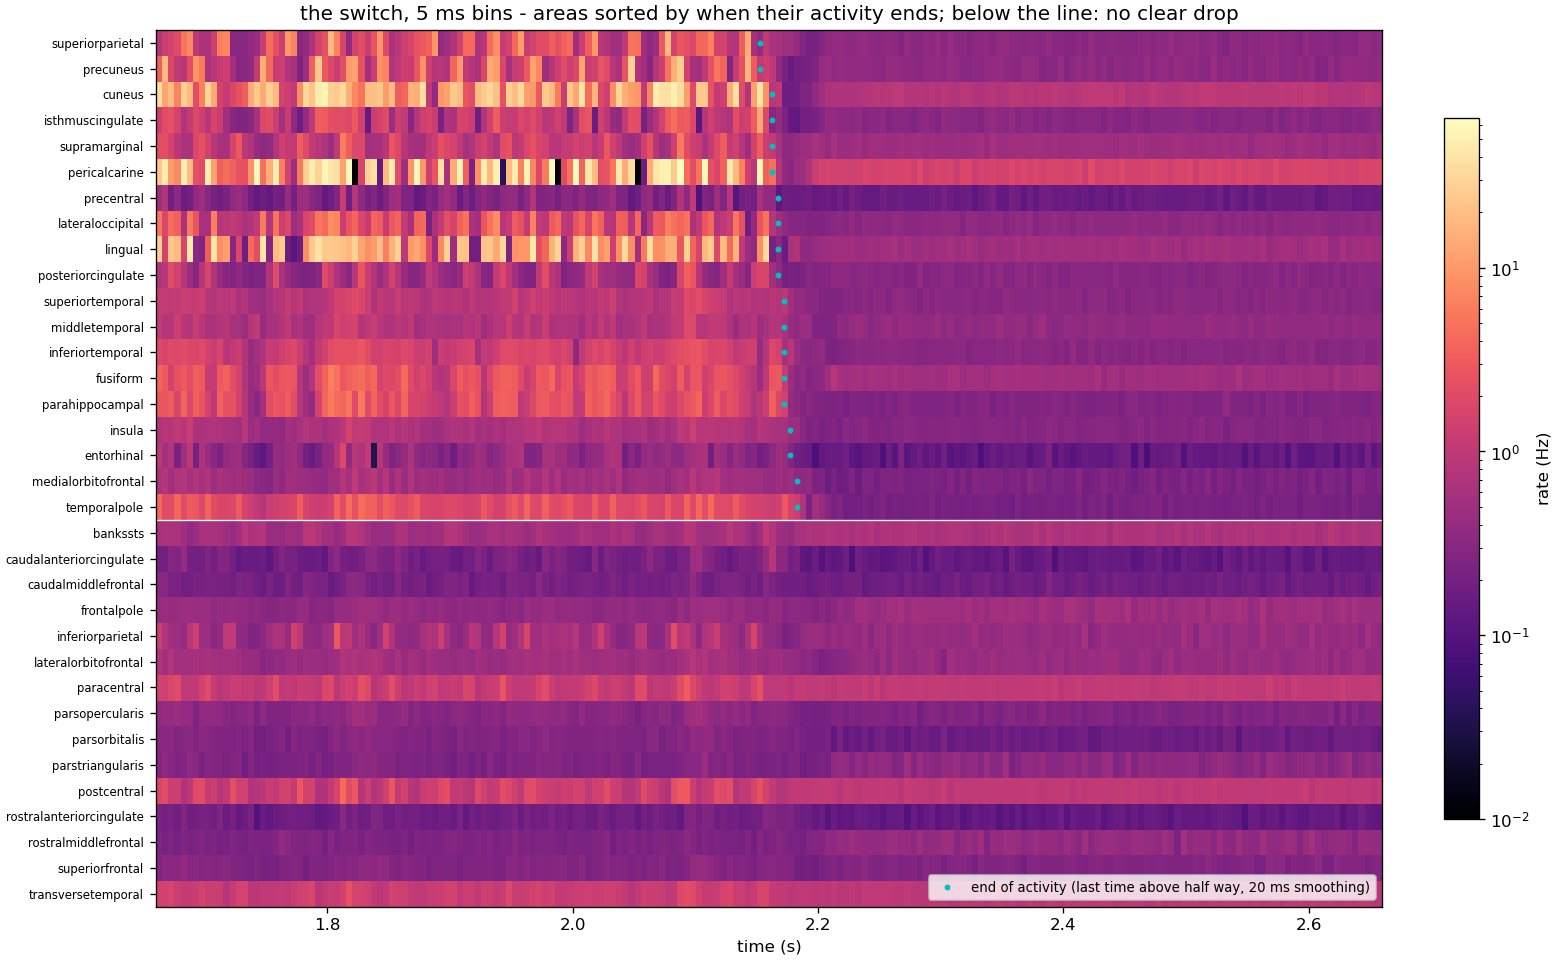

In [22]:
# Figure 6.5 - the first switch, sub016_L: areas sorted by when their activity ends
show_figure("fullscale/sub016_L/state_switch_zoom.png", width=980)

Figure 6.5, the first switch: 19 areas stop within 30 ms of each other (2.15-2.18 s) - superior
parietal and precuneus first, then cuneus, pericalcarine and the rest of visual cortex, temporal pole
and medial orbitofrontal cortex last. In `sub007_L` only 13 areas took part, in another order
(pericalcarine and cuneus first, posterior cingulate last), and postcentral, which led the bursting
there, is not among them here.

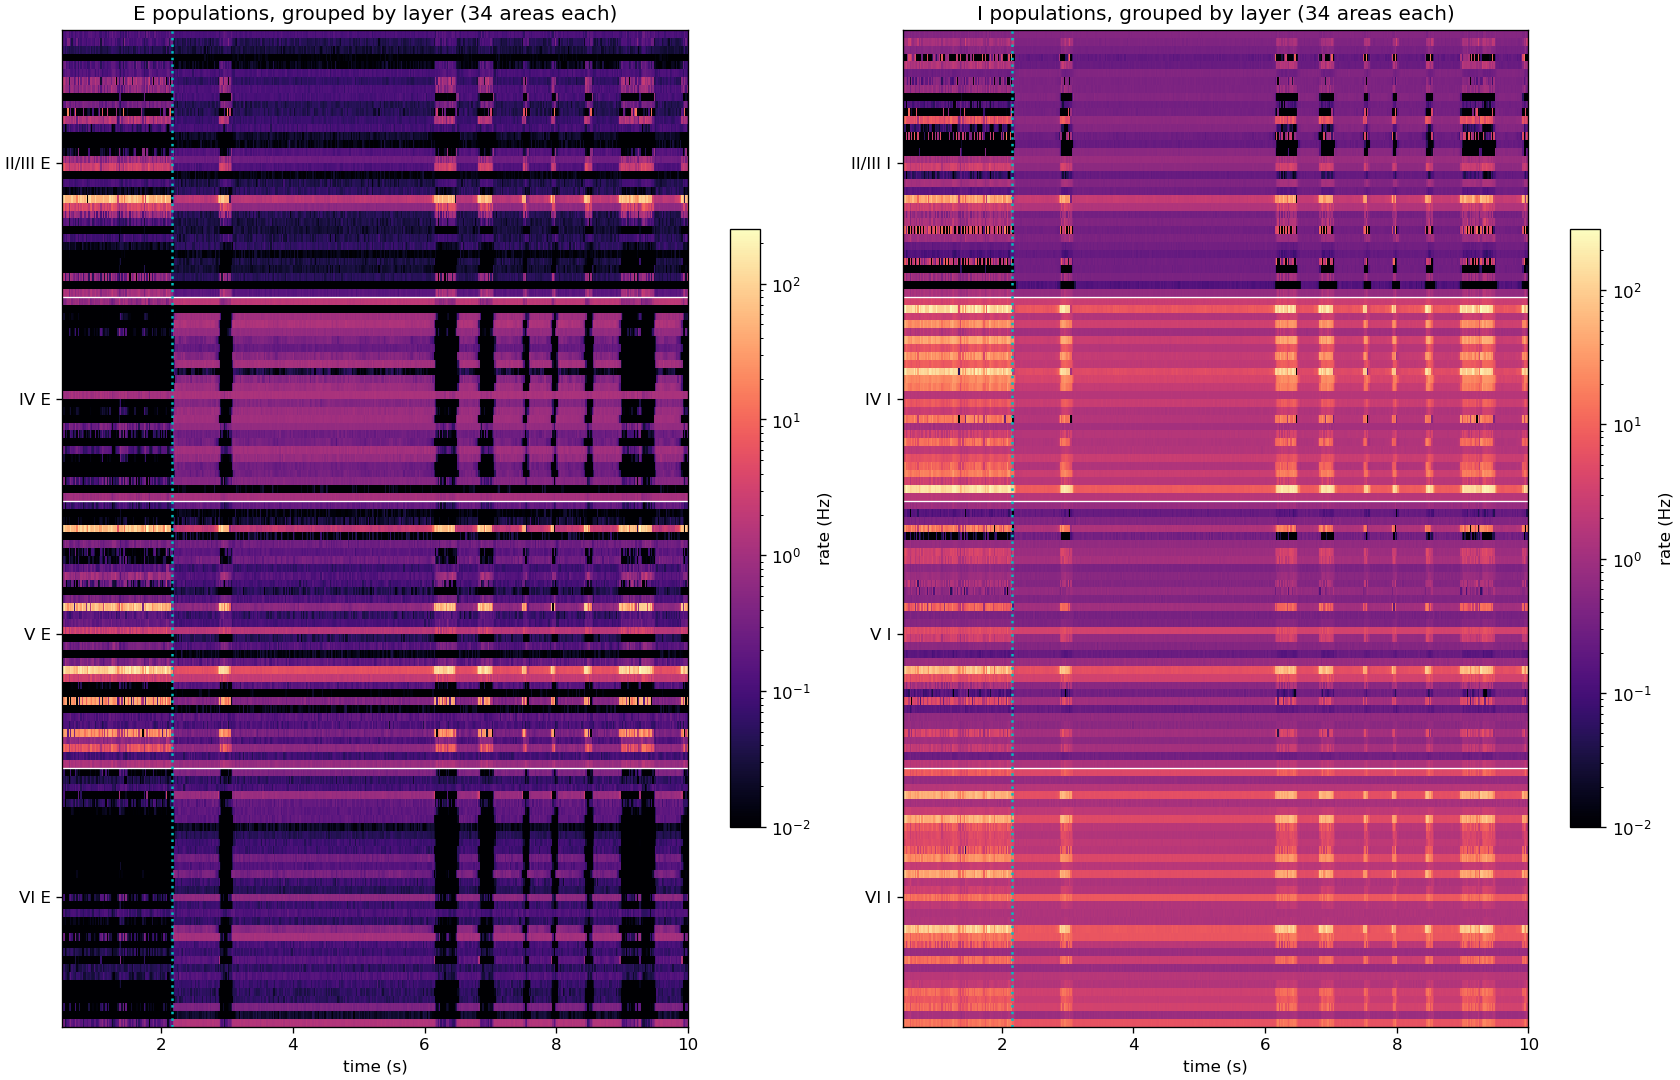

In [23]:
# Figure 6.6 - every population over time, sub016_L, grouped by layer: E (left) and I (right)
show_figure("fullscale/sub016_L/state_switch_layers.png", width=980)

Figure 6.6 resolves the populations, grouped by layer. In the active state
the excitatory populations of layers II/III and V burst while those of layers IV and VI are silent
(black); in the quiet state layers IV and VI E fire at a low rate. Every return to the active state
silences them again.

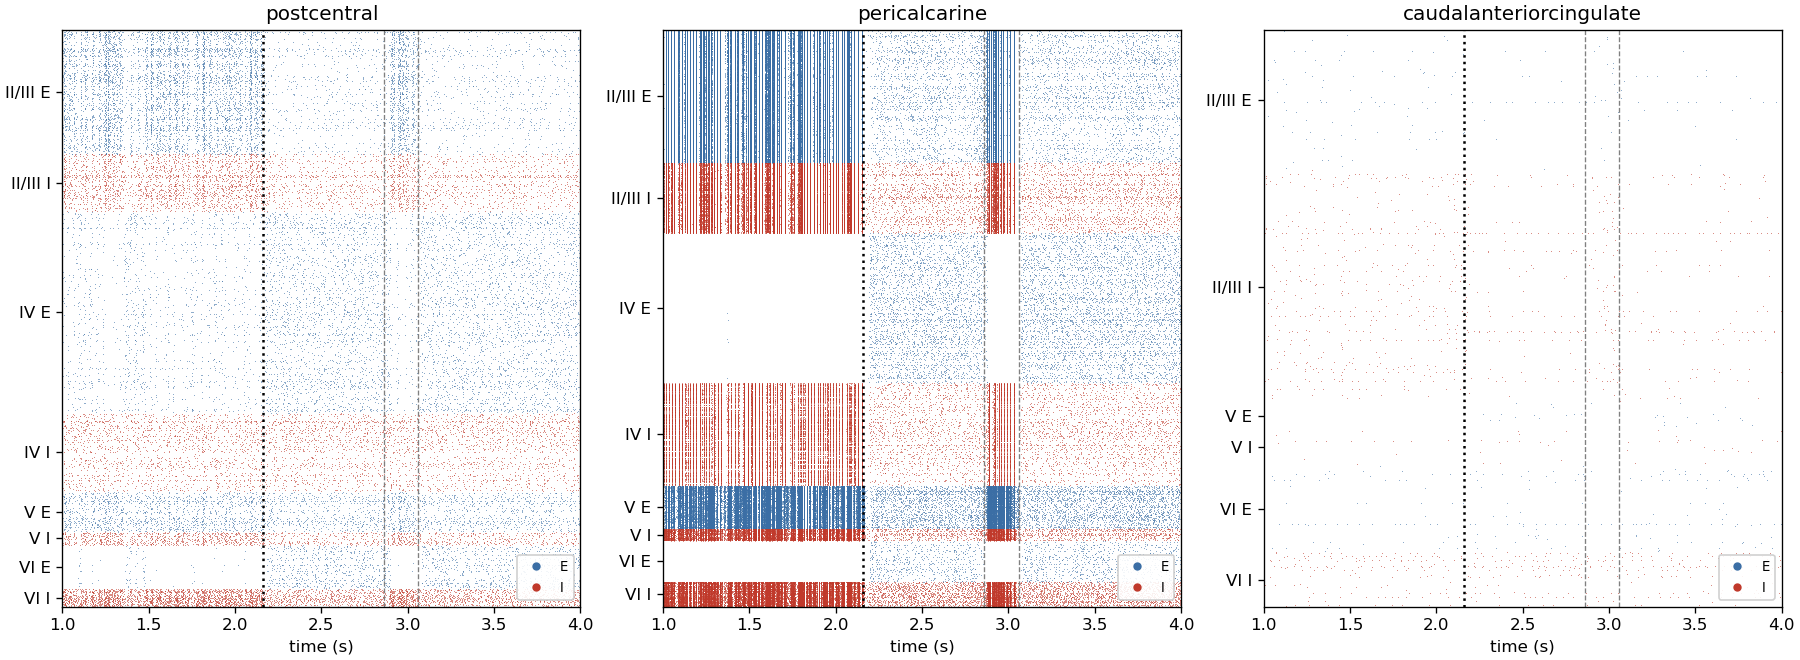

In [24]:
# Figure 6.7 - spikes, sub016_L, postcentral, pericalcarine, caudal anterior cingulate
show_figure("fullscale/sub016_L/state_switch_rasters.png", width=980)

Figure 6.7: each dot is a spike; each row is one neuron, 5% of the neurons of each population that
fired at least once, in three areas from 1 to 4 s - dotted: the first switch; dashed: the return to
the active state at 2.86-3.06 s:

- **postcentral**: no volleys. Before the switch layer II/III E fires in loosely
  synchronous patches and layer VI E is silent; after it, irregular firing in every layer - except
  during the return, when layer VI E falls silent again;
- **pericalcarine**: dense population bursts with layers IV E and VI E silent; after the switch every
  layer fires irregularly, and the 200 ms return reproduces the active pattern, layer IV E silent
  included;
- **caudal anterior cingulate**: sparse throughout - the switch does not reach every area.

### `sub011_R` - never quiet

The third hemisphere is one of the 23 that stay in the active state. It is shown because it comes
closest to leaving it: of the 23 it has the lowest mean rate and the largest fluctuations. Figures 6.8-6.12
are its versions of 6.1, 6.3, 6.4, 6.6 and 6.7; with no switch there is no zoom, and with one state
no statistics per state.

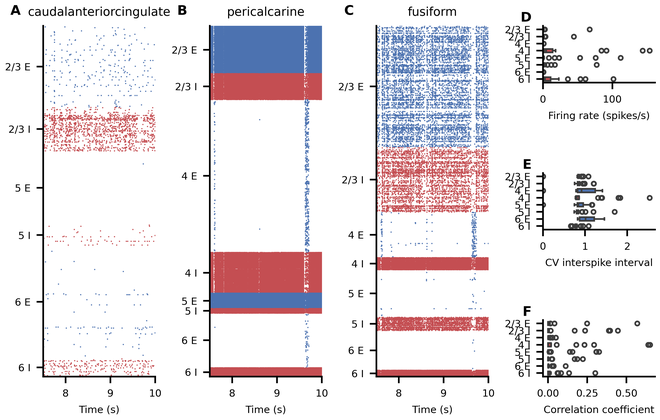

In [25]:
# Figure 6.8 - the server's own summary figure, sub011_R
show_figure("fullscale/sub011_R/server_spike_statistics.png", width=660)

Figure 6.8: in the last 2.5 s pericalcarine and fusiform burst densely while layers IV E and VI E are
silent - except for a brief pause near 9.65 s (and a shorter one at 7.55 s), in which the bursting
stops and layer IV E fires instead.

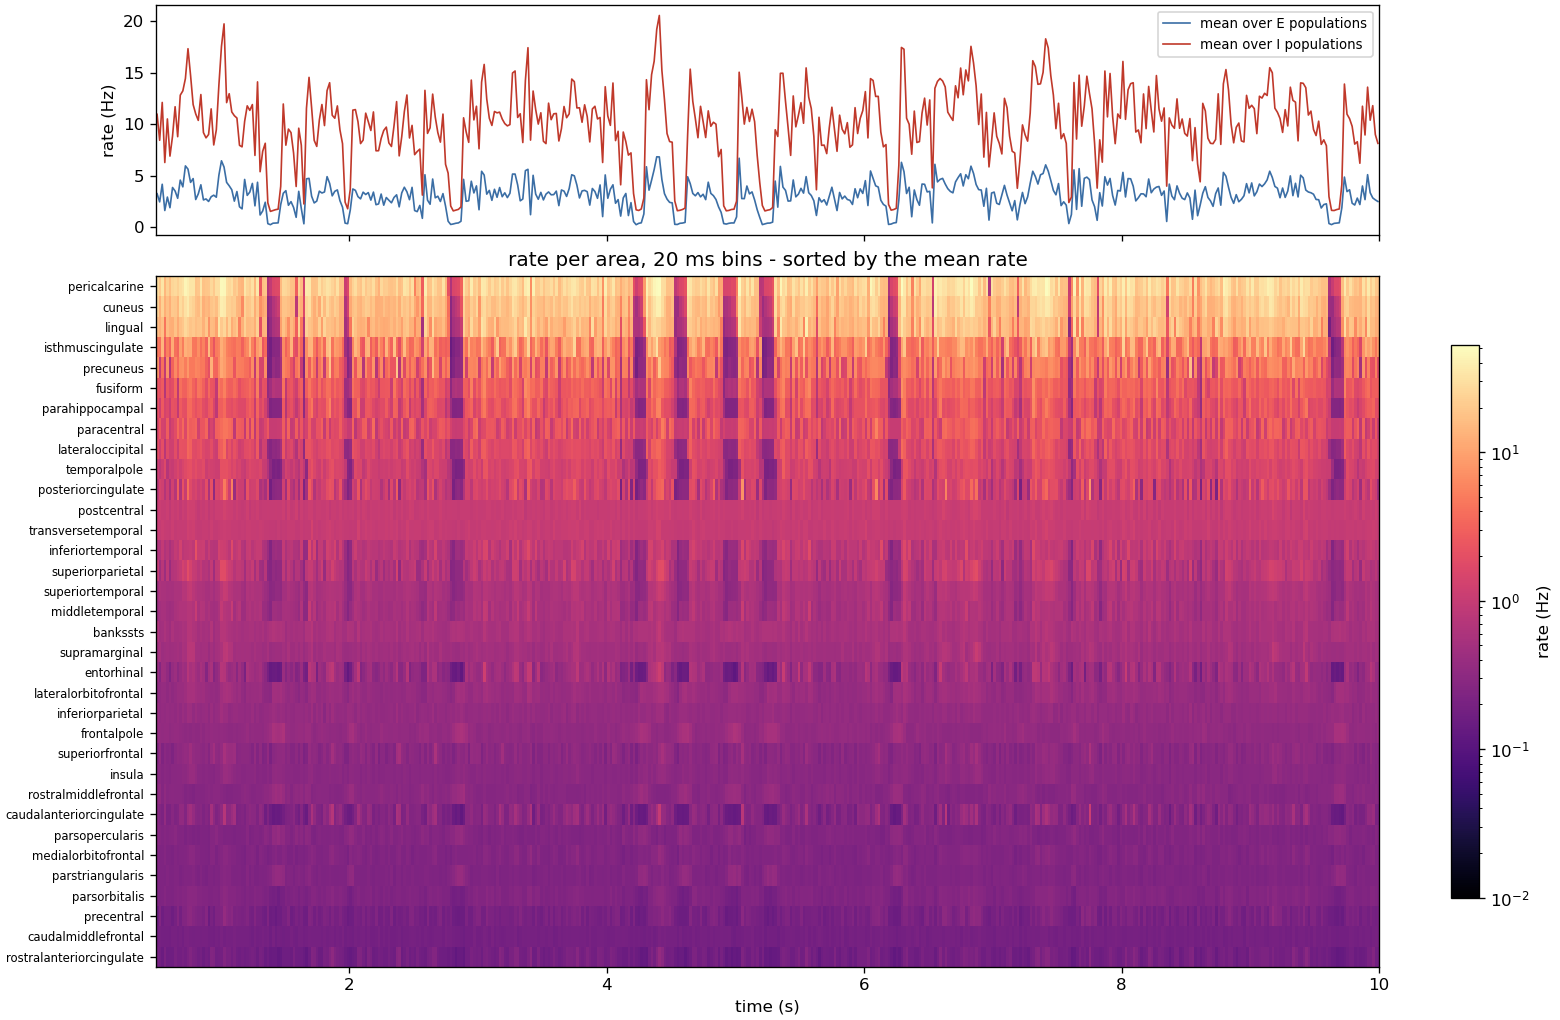

In [26]:
# Figure 6.9 - rate over time, sub011_R: the whole hemisphere (top) and every area (bottom)
show_figure("fullscale/sub011_R/state_switch_areas.png", width=980)

Figure 6.9: a group of areas much like that of `sub016_L` - visual cortex (pericalcarine, cuneus,
lingual), isthmus and posterior cingulate, precuneus, fusiform, parahippocampal - bursts for the whole
run: E 3.1 Hz and I 9.8 Hz on average, no population silent, the fastest at 154 Hz. About ten times
the whole hemisphere pauses for up to 100 ms (the dark vertical stripes): its mean rate drops to the
level of the quiet state, and recovers. No pause lasts the 200 ms that would count as quiet.

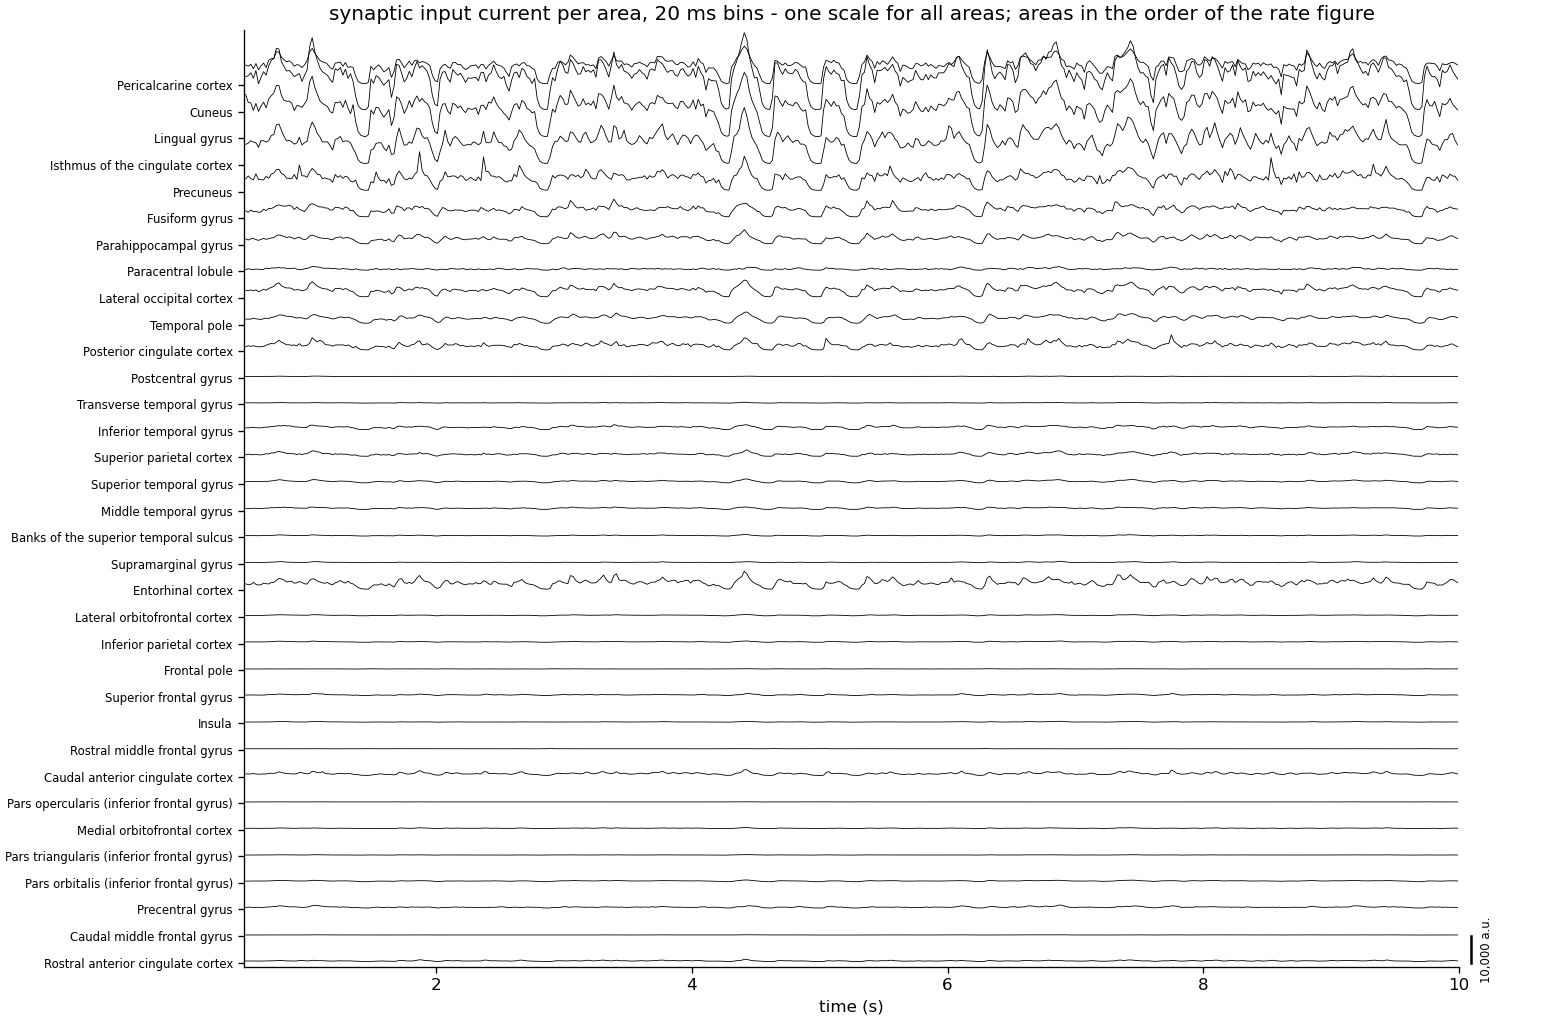

In [27]:
# Figure 6.10 - synaptic input current per area, sub011_R: one trace per area
show_figure("fullscale/sub011_R/synaptic_currents.png", width=980)

Figure 6.10, on the same scale: without a change of state, the input never goes flat. The posterior
medial group - pericalcarine, cuneus, lingual, isthmus of the cingulate, precuneus - fluctuates
strongly for the whole run (cuneus up to about 30,000), and the pauses of Figure 6.9 appear as dips
shared by these traces (around 1.4, 2.8, 4.25, 5.25, 6.2 and 9.65 s); the strongest shared peak
follows at 4.4 s, as the bursting restarts across the hemisphere. Frontal, sensorimotor and lateral
temporal areas are nearly flat.

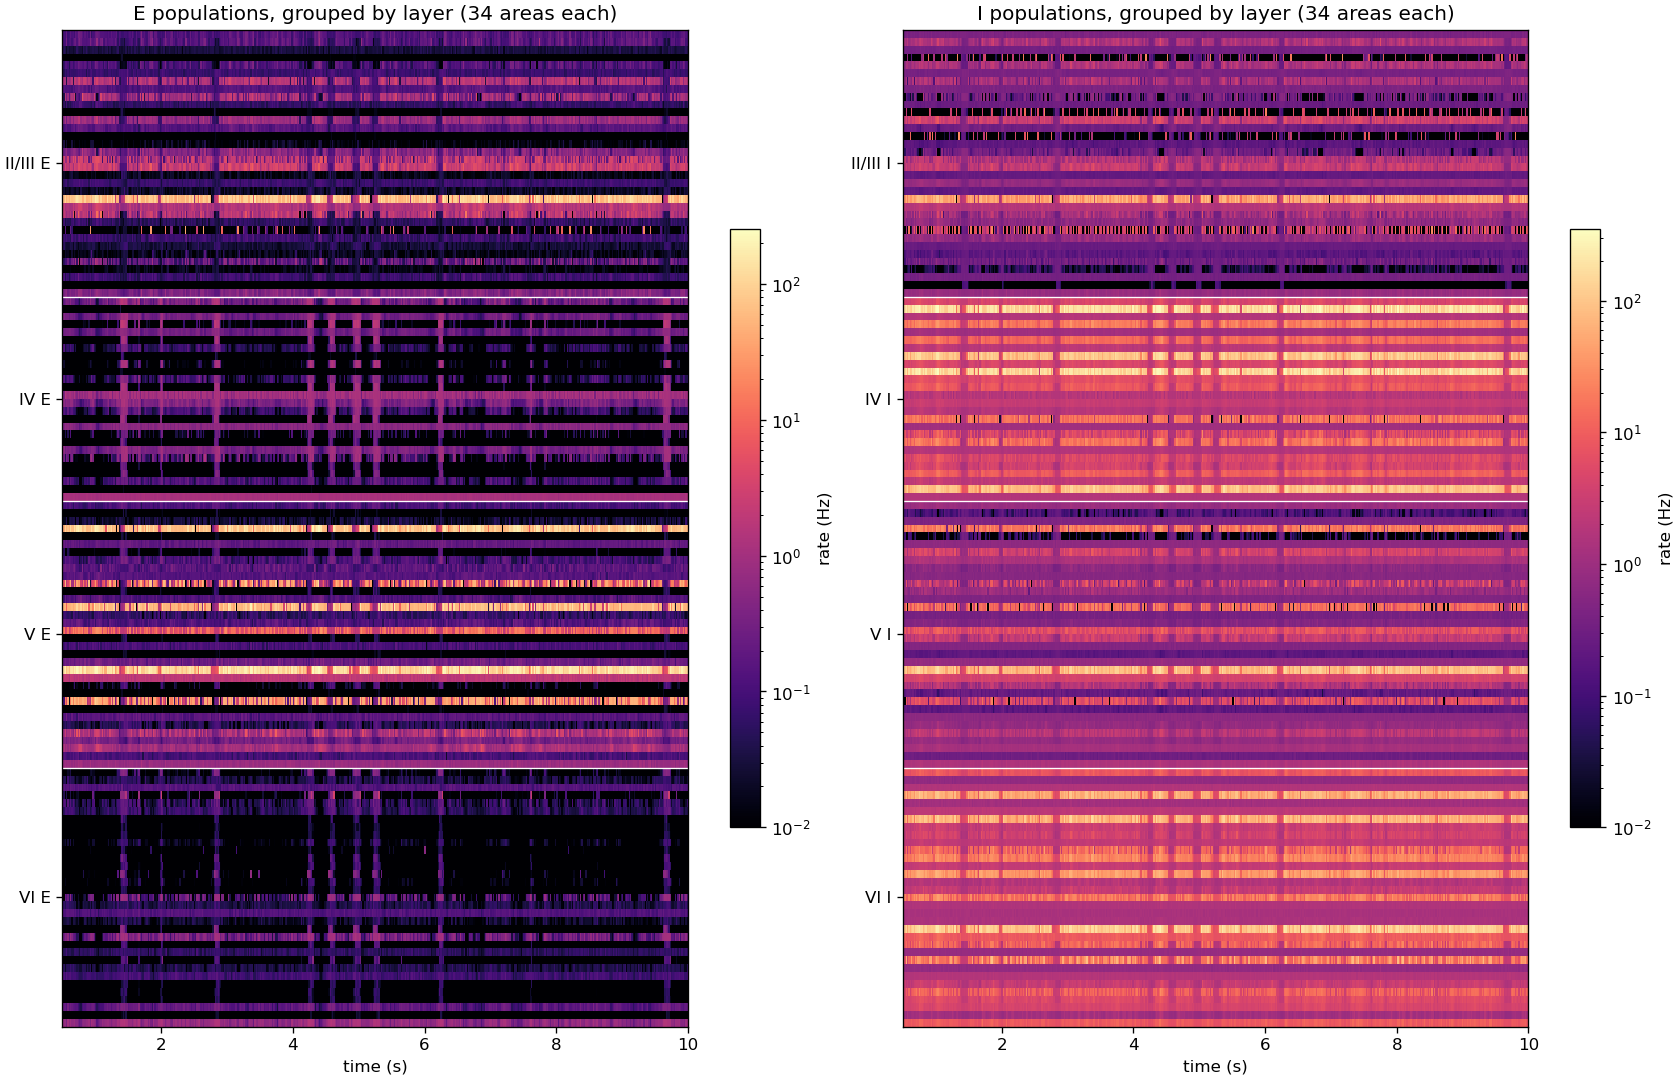

In [28]:
# Figure 6.11 - every population over time, sub011_R, grouped by layer: E (left) and I (right)
show_figure("fullscale/sub011_R/state_switch_layers.png", width=980)

Figure 6.11: each pause has the layer pattern of the quiet state. Layers IV and VI E, silent in the
bursts, fire a short volley in every pause (the thin vertical stripes in the left panel), while layers
II/III and V stop. The network touches the quiet state and is back to bursting within 100 ms - where
`sub016_L` stayed for 0.3-3.1 s at a time and `sub007_L` for good.

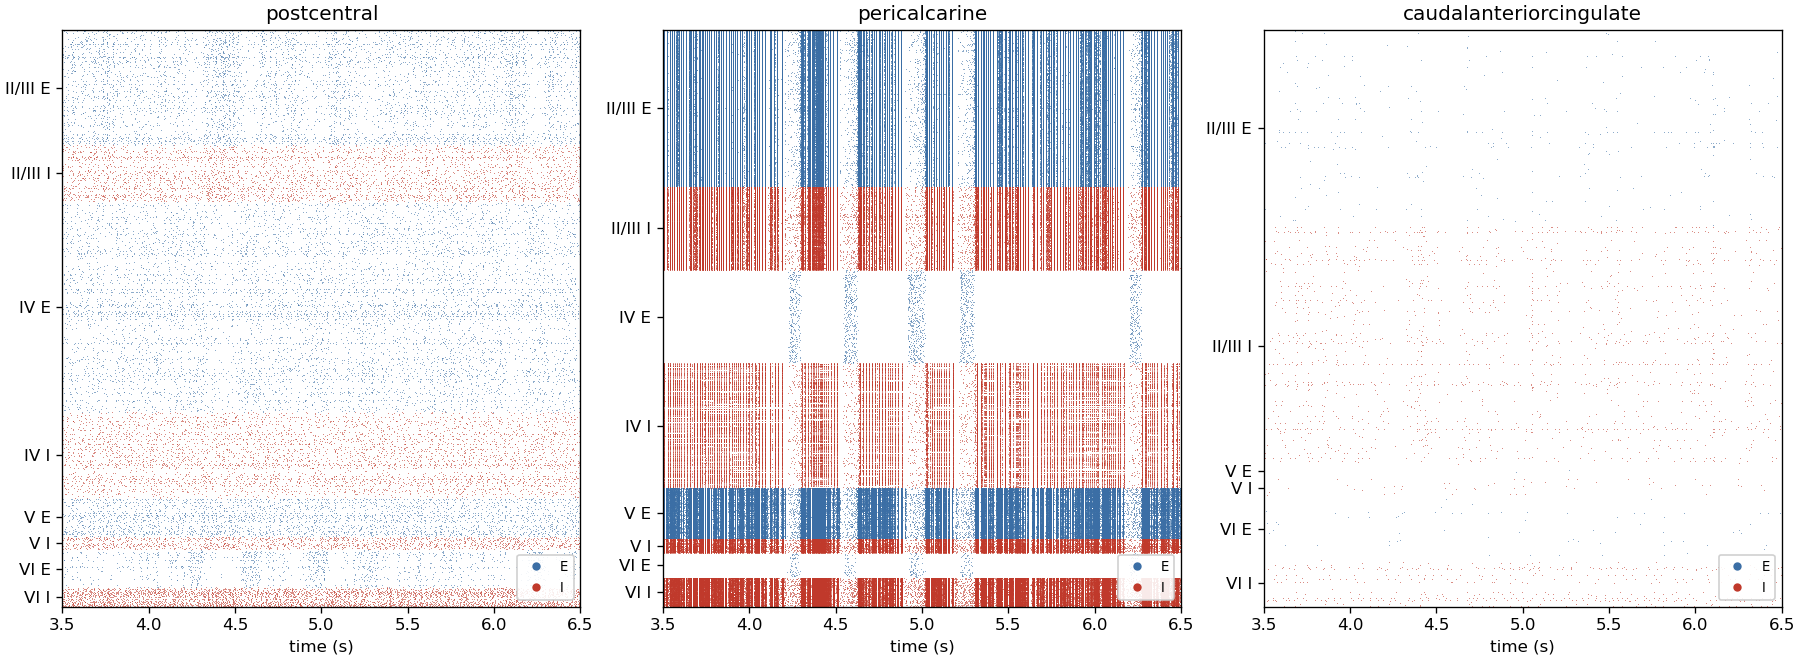

In [29]:
# Figure 6.12 - spikes, sub011_R, the three areas of Figure 6.7
show_figure("fullscale/sub011_R/state_switch_rasters.png", width=980)

Figure 6.12, 3.5-6.5 s: pericalcarine bursts throughout, with layer IV E silent except in the pauses
(around 4.25, 4.6, 4.95, 5.25 and 6.2 s), where it fires a brief volley while the bursting stops;
postcentral fires irregularly, without synchronous volleys; caudal anterior cingulate is sparse, as in
`sub016_L`.

**Which state a hemisphere is in is set by its connectome.** The cohort's 30 hemispheres share every
parameter but the connectome. 23 stay in the active state (mean excitatory rate 3.0-9.9 Hz), 5 sit in
the quiet state from the start (0.4 Hz), and two change state: `sub007_L` once, `sub016_L`
16 times. The parameters are the repository defaults and were not tuned to this cohort.

### Functional connectivity: a tool, not the result

The analysis stage also scored each run's FC, computed from the areas' synaptic input currents,
against the person's own resting-state fMRI (Figures 6.13 and 6.14). The cohort's median is r = 0.20, and
the two hemispheres that change state are its two extremes:

| | `sub007_L` | `sub016_L` | `sub011_R` |
|---|---|---|---|
| r, whole run (the server's score) | **0.47** | **-0.08** | 0.12 |
| r within the active state | 0.15 | 0.28 | 0.12 |
| r within the quiet state | 0.20 | 0.01 | - |
| mean simulated correlation | 0.76 | 0.89 | 0.70 |
| r of the simulated BOLD | 0.06 | 0.28 | 0.29 |

Neither extreme survives a closer look. A change of state moves the current of every active area at
once, so it makes the simulated matrix positive almost everywhere (mean 0.76 and 0.89) and dominates
the score: one switch gives 0.47 in one person, sixteen give -0.08 in another, and within either state
the numbers fall back to 0.01-0.28. The simulated BOLD orders the runs differently again. A single FC
number from 10 s, with or without a change of state, is not a model fit - the FC tools are meant for
long, stationary runs (4.5).

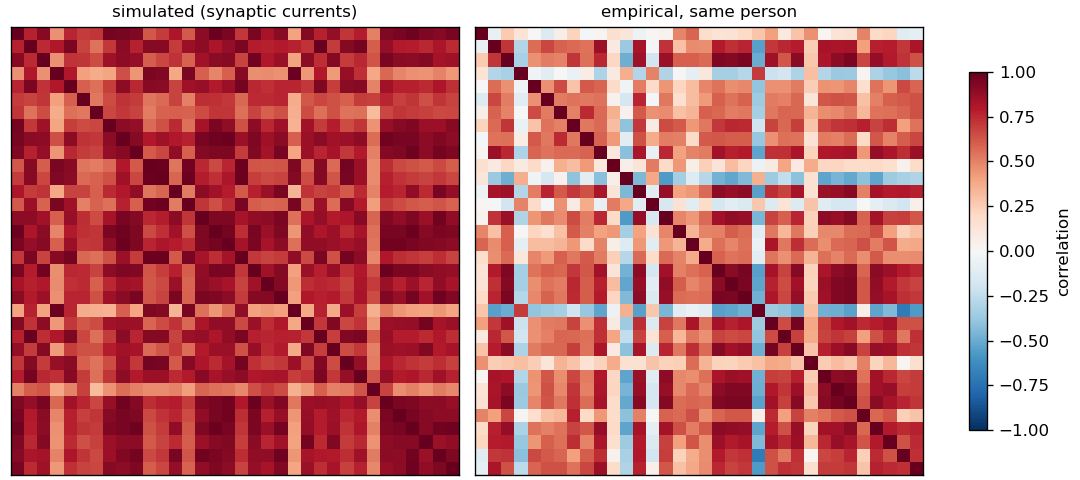

In [30]:
# Figure 6.13 - functional connectivity, simulated and empirical: sub007_L
show_figure("fullscale/sub007_L/fc_matrices.png", width=700)

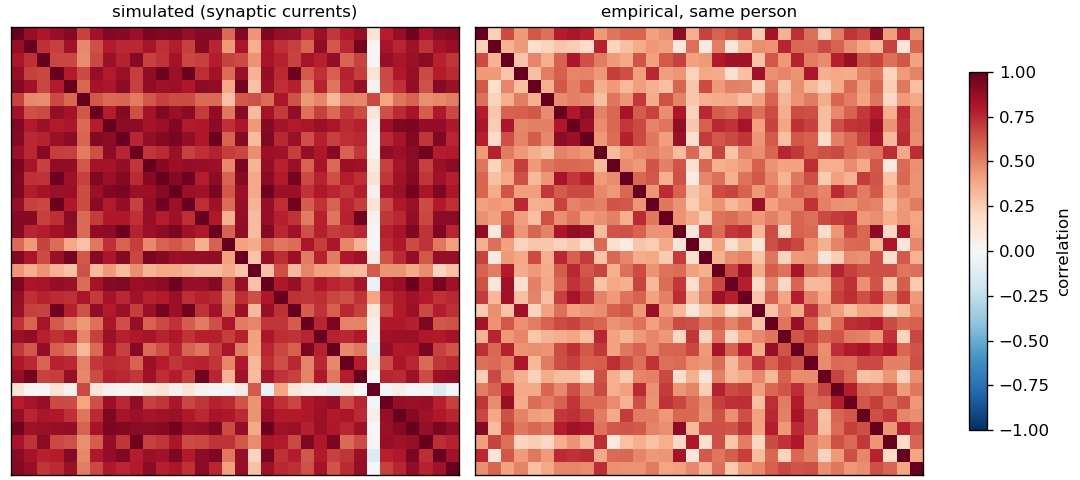

In [31]:
# Figure 6.14 - functional connectivity, simulated and empirical: sub011_R
show_figure("fullscale/sub011_R/fc_matrices.png", width=700)

---

## Summary

| | |
|---|---|
| What the model is | 34 areas x 4 layers x E/I, anatomy from cytoarchitecture and tractography, no free parameters fitted to the output |
| How you use it | one experiment file, three stages, hash-addressed results |
| What you ran | a healthy cortex, a few seconds, ~200 figures - and, in Appendix B, an amyloid-burdened one |
| What it showed | at full scale, three hemispheres with identical parameters in different network states - one switching once, one back and forth, one never - set by their connectomes; in Appendix B, how the downscaling compensation itself can bias the comparison of two conditions |
| What it could not show | few-percent effects - spectra, functional connectivity - at this size and duration |
| How to go further | longer runs, full scale, many seeds - a server with the Snakemake workflow of Part 6; 6.2 shows three such runs |

Two habits are worth more than any figure in this notebook. **A downscaled network is a different
model** - verify its working point before interpreting anything. **An effect that does not survive a
change of random seed is not an effect** - measure your noise floor before naming a finding.

---

## References

**The model**

- Pronold, J., van Meegen, A., Shimoura, R. O., Vollenbröker, H., Senden, M., Hilgetag, C. C.,
  Bakker, R., & van Albada, S. J. (2024). Multi-scale spiking network model of human cerebral
  cortex. *Cerebral Cortex*. https://doi.org/10.1093/cercor/bhae409
- Schmidt, M., Bakker, R., Shen, K., Bezgin, G., Diesmann, M., & van Albada, S. J. (2018). A
  multi-scale layer-resolved spiking network model of resting-state dynamics in macaque visual
  cortical areas. *PLoS Computational Biology*, 14(10), e1006359.

**Cortical dynamics in vivo**

- Barth, A. L., & Poulet, J. F. A. (2012). Experimental evidence for sparse firing in the neocortex.
  *Trends in Neurosciences*, 35(6), 345-355.
- Brunel, N. (2000). Dynamics of sparsely connected networks of excitatory and inhibitory spiking
  neurons. *Journal of Computational Neuroscience*, 8(3), 183-208.
- de Kock, C. P. J., Bruno, R. M., Spors, H., & Sakmann, B. (2007). Layer- and cell-type-specific
  suprathreshold stimulus representation in rat primary somatosensory cortex. *Journal of
  Physiology*, 581(1), 139-154.
- Ecker, A. S., Berens, P., Keliris, G. A., Bethge, M., Logothetis, N. K., & Tolias, A. S. (2010).
  Decorrelated neuronal firing in cortical microcircuits. *Science*, 327(5965), 584-587.
- Gentet, L. J., Avermann, M., Matyas, F., Staiger, J. F., & Petersen, C. C. H. (2010). Membrane
  potential dynamics of GABAergic neurons in the barrel cortex of behaving mice. *Neuron*, 65(3),
  422-435.
- Harris, K. D., & Thiele, A. (2011). Cortical state and attention. *Nature Reviews Neuroscience*,
  12(9), 509-523.
- Renart, A., de la Rocha, J., Bartho, P., Hollender, L., Parga, N., Reyes, A., & Harris, K. D.
  (2010). The asynchronous state in cortical circuits. *Science*, 327(5965), 587-590.
- Sakata, S., & Harris, K. D. (2009). Laminar structure of spontaneous and sensory-evoked population
  activity in auditory cortex. *Neuron*, 64(3), 404-418.
- Softky, W. R., & Koch, C. (1993). The highly irregular firing of cortical cells is inconsistent with
  temporal integration of random EPSPs. *Journal of Neuroscience*, 13(1), 334-350.
- van Vreeswijk, C., & Sompolinsky, H. (1996). Chaos in neuronal networks with balanced excitatory and
  inhibitory activity. *Science*, 274(5293), 1724-1726.

**Downscaling**

- van Albada, S. J., Helias, M., & Diesmann, M. (2015). Scalability of asynchronous networks is
  limited by one-to-one mapping between effective connectivity and correlations. *PLoS Computational
  Biology*, 11(9), e1004490.
- Potjans, T. C., & Diesmann, M. (2014). The cell-type specific cortical microcircuit. *Cerebral
  Cortex*, 24(3), 785-806.

**Alzheimer's disease dynamics**

- Palop, J. J., & Mucke, L. (2016). Network abnormalities and interneuron dysfunction in Alzheimer
  disease. *Nature Reviews Neuroscience*, 17(12), 777-792.
- Jeong, J. (2004). EEG dynamics in patients with Alzheimer's disease. *Clinical Neurophysiology*,
  115(7), 1490-1505.
- Iaccarino, H. F., et al. (2016). Gamma frequency entrainment attenuates amyloid load and modifies
  microglia. *Nature*, 540, 230-235.

**Field potentials**

- Mazzoni, A., Lindén, H., Cuntz, H., Lansner, A., Panzeri, S., & Einevoll, G. T. (2015). Computing
  the local field potential (LFP) from integrate-and-fire network models. *PLoS Computational
  Biology*, 11(12), e1004584. https://doi.org/10.1371/journal.pcbi.1004584

**Haemodynamics and whole-brain modelling**

- Buxton, R. B., Wong, E. C., & Frank, L. R. (1998). Dynamics of blood flow and oxygenation changes
  during brain activation: the balloon model. *Magnetic Resonance in Medicine*, 39(6), 855-864.
- Deco, G., Jirsa, V. K., & McIntosh, A. R. (2011). Emerging concepts for the dynamical organization
  of resting-state activity in the brain. *Nature Reviews Neuroscience*, 12(1), 43-56.

**Tools**

- NEST: https://nest-simulator.readthedocs.io
- NNMT (mean-field toolbox): https://nnmt.readthedocs.io
- Snakemake: https://snakemake.readthedocs.io

# Appendix A - Downscaling and its DC compensation

A downscaled network keeps `N_scaling` $= n$ of the neurons and `K_scaling` $= k$ of each neuron's
in-degree (`tutorial_CN`: $n = 0.01$, $k = 0.1$). Notation: population $i$ (area x layer x E/I) has
$N_i$ neurons and receives $S_{ij}$ synapses from population $j$, so its mean in-degree is
$K_{ij} = S_{ij}/N_i$; each such synapse has the PSC amplitude $J_{ij}$ (pA). The external Poisson
drive has $K_{\mathrm{ext},i}$ inputs per neuron, each at rate $\nu_{\mathrm{ext},i}$ with amplitude
$J_{\mathrm{ext},i}$. Rates $\nu$ are in spikes/s.

### A.1 What `Network.scaleNetwork()` changes

$$N_i' = \operatorname{round}(n\,N_i), \qquad S_{ij}' = \operatorname{round}(n\,k\,S_{ij}), \qquad
S_{\mathrm{ext},i}' = \operatorname{round}(n\,k\,S_{\mathrm{ext},i})$$

so the in-degrees become $K_{ij}' = S_{ij}'/N_i' \approx k\,K_{ij}$, and every weight - recurrent,
external, and their standard deviations - is divided by the same factor:

$$J_{ij}' = J_{ij}/k^{\gamma}, \qquad J_{\mathrm{ext},i}' = J_{\mathrm{ext},i}/k^{\gamma},$$

with $\gamma = 1/2$ for `scaling_type = "sqrt"` and $\gamma = 1$ for `"linear"`.

Nothing else changes: neuron parameters, delays, and the external rates $\nu_{\mathrm{ext}}$, which
`externalRates()` sets from `eta_ext` *before* scaling. One side effect: the connection probability
between two populations, $p_{ij} = K_{ij}/N_j$, becomes $K_{ij}'/N_j' \approx (k/n)\,p_{ij}$ - for
`tutorial_CN` the network is ten times *denser* than the full one (A.5).

### A.2 Mean and variance of the input

The neurons are `iaf_psc_exp`:

$$\tau_m \frac{dV}{dt} = -(V - E_L) + \frac{\tau_m}{C_m}\big(I_{\mathrm{syn}}(t) + I_e\big), \qquad
\frac{dI_{\mathrm{syn}}}{dt} = -\frac{I_{\mathrm{syn}}}{\tau_s} + \sum_{j}\sum_{s} J_j\,\delta(t - t_j^s - d_j)$$

A spike of a synapse with amplitude $J$ produces the current $J e^{-t/\tau_s}$: it carries the charge
$\int J e^{-t/\tau_s}dt = J\tau_s$ and contributes $\int (J e^{-t/\tau_s})^2 dt = J^2\tau_s/2$ to the
variance. If the $K_{ij}$ inputs fire as independent Poisson processes at rate $\nu_j$, Campbell's
theorem gives the stationary mean and variance of $I_{\mathrm{syn}}$:

$$\mu_i = \sum_j K_{ij}\,J_{ij}\,\tau_s\,\nu_j \;+\; K_{\mathrm{ext},i}\,J_{\mathrm{ext},i}\,\tau_s\,\nu_{\mathrm{ext},i}$$

$$\sigma_i^2 = \sum_j K_{ij}\,\overline{J_{ij}^2}\,\frac{\tau_s}{2}\,\nu_j \;+\;
K_{\mathrm{ext},i}\,\overline{J_{\mathrm{ext},i}^2}\,\frac{\tau_s}{2}\,\nu_{\mathrm{ext},i}$$

with $\overline{J^2} = J^2(1 + 0.1^2)$ for the weight spread `PSP_rel = 0.1`, the recurrent sums
multiplied by `p_transmit`, and $\tau_s$ = `tau_syn_ex` or `tau_syn_in` of the *receiving* neuron,
depending on whether population $j$ is excitatory or inhibitory. (With $J$ in pA, $\tau_s$ in ms
and $\nu$ in 1/s, $\mu$ is
$10^{-3}\times$ this in pA - exactly `Network._meanSynapticInput()`.) In voltage, the free membrane
potential sits at $E_L + \tau_m(\mu_i + I_e)/C_m$; `eta_ext` is defined through the external term,
$\tau_m K_{\mathrm{ext}} J_{\mathrm{ext}} \tau_s \nu_{\mathrm{ext}}/C_m = \eta_{\mathrm{ext}}\,(V_{\mathrm{th}} - E_L)$.

Insert A.1 with the rates held fixed: every term is multiplied by the same power of $k$,

$$\mu_i' = k^{\,1-\gamma}\,\mu_i, \qquad \sigma_i'^2 = k^{\,1-2\gamma}\,\sigma_i^2 .$$

| `scaling_type` | weight | mean input | input s.d. | at $k = 0.1$ |
|---|---|---|---|---|
| `"sqrt"` | $J/\sqrt{k}$ | $\sqrt{k}\,\mu$ | $\sigma$ | mean 32 %, s.d. 100 % |
| `"linear"` | $J/k$ | $\mu$ | $\sigma/\sqrt{k}$ | mean 100 %, s.d. 316 % |

No single $\gamma$ keeps both. The mean, unlike the variance, can be put back with a constant current,
so the tutorial scales with `"sqrt"` (van Albada et al. 2015) and adds the missing mean as DC (A.3).
With `"linear"` the mean is kept and the DC current is zero up to rounding, but the fluctuations
grow by $1/\sqrt{k}$ - at $k = 0.1$ the network is driven by noise three times stronger than the
full one.

The price of `"sqrt"` is larger individual synapses. For the default excitatory neuron
($C_m = 220$ pF, $\tau_m = 10$ ms, $\tau_s = 2$ ms) a PSP of `PSP_e = 0.1` mV is a PSC of about
16.4 pA; at $k = 0.1$ it becomes 52 pA, a PSP of 0.32 mV. That is still small against the 25 mV from
reset to threshold, so the description by $\mu$ and $\sigma$ alone (the diffusion approximation)
remains reasonable - but the higher cumulants of the input, $\propto K J^m$, grow as $k^{1 - m/2}$:
the input of a scaled neuron is somewhat more "shot-like".

### A.3 The DC current

`Network.extraDCforScaledNetwork()` adds the missing mean to the bias current `I_e` of every
population:

$$I_{\mathrm{DC},i} = \mu_i^{\mathrm{full}}(\hat\nu) - \mu_i^{\mathrm{scaled}}(\hat\nu)$$

Both means use the same rates $\hat\nu$ - those of the *full-scale* network, read from
`net_params["fullscale_rates"]` - $\mu^{\mathrm{full}}$ with the in-degrees and weights before
scaling, $\mu^{\mathrm{scaled}}$ with those actually realised after it, so the DC current also absorbs
the rounding of small synapse numbers. Without rounding, for `"sqrt"`,

$$I_{\mathrm{DC},i} = (1 - \sqrt{k})\,\mu_i^{\mathrm{full}}(\hat\nu)
= (1-\sqrt{k})\Big[\sum_j K_{ij} J_{ij}\tau_s\hat\nu_j + K_{\mathrm{ext},i}J_{\mathrm{ext},i}\tau_s\nu_{\mathrm{ext},i}\Big]$$

At $k = 0.1$, $1 - \sqrt{k} = 0.68$: about 70 % of the recurrent and external mean input is
replaced by a constant. Populations emptied by rounding ($N_i' = 0$) get none. $\tau_s$ belongs to the
receiving neuron, so a neuron type with its own synaptic time constants (`neuron_types`) gets its own
DC current (`dc_drive_types`).

When the scaled network fires at rates $\nu$, a neuron of population $i$ therefore receives the mean

$$\mu_i'(\nu) + I_{\mathrm{DC},i} = \mu_i^{\mathrm{full}}(\hat\nu)
\;+\; \sqrt{k}\,\sum_j K_{ij} J_{ij}\tau_s\,(\nu_j - \hat\nu_j),$$

which equals the full-scale mean input exactly when $\nu = \hat\nu$. Two consequences:

- **The rates must belong to the experiment.** The DC current stands in for recurrent input. If the
  rates in the file are off by $\delta\nu$, every population is shifted by
  $(1-\sqrt{k})\sum_j K_{ij}J_{ij}\tau_s\,\delta\nu_j$. In this inhibition-dominated network
  (`g = -5`, so $\sum_j K_{ij}J_{ij} < 0$ for most $i$) rates that are too high produce too little,
  or negative, DC and the network falls silent; rates that are too low produce too much and it runs
  away. The model's `simulated_data/base_theory_rates.pkl` belongs to a single configuration
  (`eta_ext` = 1.1, long-range gains 1.0 / 2.0);
  every experiment here ships its own file in `experiments/fullscale_rates/`, and 5.6 shows how to
  generate one.
- **The recurrent feedback is weakened.** The DC part is frozen at $\hat\nu$; only the remaining
  $\sqrt{k}$ of the mean input follows the network's rates. A.5 shows why that matters.

### A.4 Finding $\hat\nu$: the fixed point of 5.6

$\hat\nu$ is what the full-scale network would do, which is the unknown. `tools/fullscale_rates.py`
treats it as a fixed point. Let $F(\nu)$ be the rates of the downscaled network simulated with the DC
current computed from $\nu$; the full-scale rates are then the solution of $\hat\nu = F(\hat\nu)$.
The script iterates

$$\nu^{(m+1)} = \nu^{(m)} + \alpha\,\big(F(\nu^{(m)}) - \nu^{(m)}\big).$$

Near the fixed point $F(\nu) \approx \hat\nu + g\,(\nu - \hat\nu)$, and the error $e = \nu - \hat\nu$
evolves as $e^{(m+1)} = [1 - \alpha(1 - g)]\,e^{(m)}$. It converges for $0 < \alpha < 2/(1-g)$, fastest at
$\alpha = 1/(1-g)$. The gain is negative - higher $\hat\nu$, more negative DC, lower simulated rates -
about $g \approx -5$ for the mean rate here, so the plain iteration ($\alpha = 1$, which needs
$|g| < 1$) oscillates with growing amplitude, while $\alpha = 1/6 \approx 0.17$, the default
`--alpha`, damps it in a few iterations. Strictly, $g$ is a matrix (one row per population); along
directions in which the populations respond weakly (eigenvalues $\lambda$ near 0) the error shrinks
only by $1 - \alpha(1-\lambda) \approx 0.83$ per iteration - about 25 iterations per factor 100,
which is why 5.6 runs 40. Each $F(\nu)$ is also a noisy simulation; its noise $\xi$ enters the update
as $\alpha\xi$, so the final estimate scatters by roughly a sixth of the noise of a single run.

### A.5 What downscaling does not preserve

The DC current fixes the *working point*: the mean input, and with it the rates. Everything that
depends on how the network responds to its own fluctuations is a different matter (van Albada et al.
2015):

- **Effective connectivity.** To linear order, a small change of rate $j$ changes rate $i$ by
  $$W_{ij} = \frac{\partial\nu_i}{\partial\nu_j}
  = K_{ij}\tau_s\Big(\frac{\partial\Phi_i}{\partial\mu_i}\,J_{ij}
  + \frac{\partial\Phi_i}{\partial\sigma_i^2}\,\frac{J_{ij}^2}{2}\Big),$$
  where $\Phi_i(\mu_i, \sigma_i)$ is the neuron's rate as a function of its input. Since $\mu$ and
  $\sigma$ are restored, the derivatives of $\Phi$ are the same; but the first term is multiplied by
  $\sqrt{k}$ (it is the part of the feedback frozen into the DC current) and the second is unchanged,
  so $W' \neq W$. The stability of the asynchronous state, oscillations and pairwise correlations are
  all governed by $W$ - in linear response the covariances are
  $C \propto (1-W)^{-1} D\,(1-W)^{-\mathsf T}$ - so they cannot all be kept. This is the formal
  reason why the collective states of 6.2 need not appear in a downscaled network, and why one that
  shows them may do so for reasons of its own (4.3).
- **Shared input.** Two neurons of population $i$ share on average $K_{ij}^2/N_j$ inputs from
  population $j$, a fraction $p_{ij} = K_{ij}/N_j$ of their inputs. After scaling this fraction is
  $(k/n)\,p_{ij}$ - ten times larger for `tutorial_CN` - and so is the input correlation it causes,
  before the recurrent inhibition decorrelates it.
- **Finite-size noise.** The population rate measured in a bin $\Delta t$ fluctuates with variance
  $\approx \nu_i / (N_i\,\Delta t)$, a factor $1/n$ (100 for `tutorial_CN`) larger after scaling. The
  smallest populations keep a few dozen neurons or fewer, and their rates are correspondingly noisy.
- **Rounding.** Populations with $n N_i < 0.5$ vanish and small synapse numbers are rounded. The DC
  current absorbs the effect on the mean; nothing absorbs it on the variance.

The downscaled network therefore approximates the full-scale one in its mean input - and so its rates -
only.

# Appendix B - Simulating an amyloid-beta distribution

## B.1 The biology

In this tutorial, excitatory neurons affected by amyloid-beta are made more excitable: their
threshold is moved closer to their resting potential (B.2).
Amyloid-beta aggregates into extracellular plaques and is one of the two defining pathologies of
Alzheimer's disease. For a *dynamical* model the important point is that it does not merely kill
neurons: well before cell death, surviving neurons in amyloid-burdened tissue show altered membrane
properties and a **lowered effective firing threshold**, and both human and mouse work reports
**network hyperexcitability** - including a several-fold increase in seizure incidence in patients
(Palop & Mucke 2016).

## B.2 The parameter mapping

The implementation does not represent amyloid chemistry. It declares an `"Abeta"` entry in `neuron_types`,
which replaces a configurable **fraction of the excitatory neurons in each population** with units whose parameters are fitted to Allen Brain Cell Atlas GLIF
recordings of amyloid-burdened cells:

| | healthy E neuron | amyloid-affected E neuron |
|---|---|---|
| $E_L$ | -70 mV | **-65 mV** |
| $V_{\mathrm{th}}$ | -45 mV | **-50 mV** |
| **distance to threshold** | **25 mV** | **15 mV** |
| $C_m$, $\tau_m$, $t_{\mathrm{ref}}$ | 220 pF, 10 ms, 2 ms | unchanged |

A 40% shorter path to threshold, and nothing else. Connectivity, weights, delays and drive are
identical between `tutorial_CN.py` and `tutorial_amyloid.py`. In a downscaled run one more thing
differs: the DC compensation, computed from each experiment's own full-scale rates (B.5).

## B.3 From an amyloid-PET scan to a parameter

`ratio_E` (and `ratio_I`) of a neuron type accepts four forms, in increasing specificity:

| Form | Example | Meaning |
|---|---|---|
| uniform | `0.15` | 15% of excitatory neurons everywhere |
| per area | `{"precuneus": 0.3, "default": 0.05}` | per-area fractions with a fallback |
| per area, per layer | `{"precuneus": {"II/III": 0.3}}` | laminar resolution |
| CSV path | `experimental_data/amyloid/amyloid_ratio.csv` | a participant's amyloid-PET map |

The CSV form is the one that makes this a patient-specific model: an individual's **amyloid-PET SUVR
map**, parcellated into Desikan-Killiany areas, becomes a per-area disease burden. The repository
bundles one derived from an ADNI participant's amyloid-PET scan.

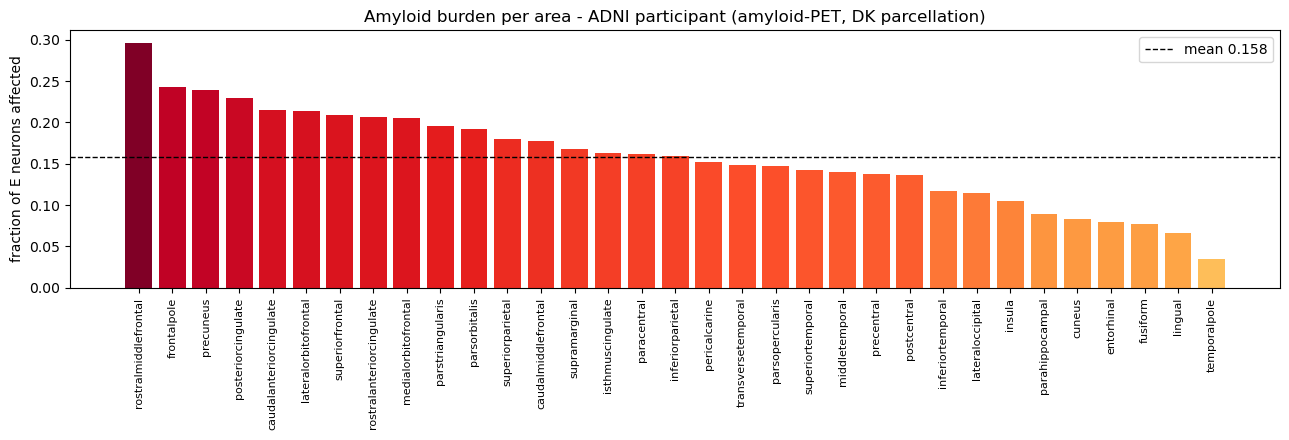

range           : 0.035 - 0.296
heaviest areas  : rostralmiddlefrontal, frontalpole, precuneus, posteriorcingulate, caudalanteriorcingulate
lightest areas  : cuneus, entorhinal, fusiform, lingual, temporalpole


In [32]:
per_area = amyloid_burden("amyloid_ratio.csv")

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.bar(range(len(per_area)), per_area.values,
       color=plt.cm.YlOrRd(0.25 + 0.75 * per_area.values / per_area.max()))
ax.set_xticks(range(len(per_area)))
ax.set_xticklabels(per_area.index, rotation=90, fontsize=8)
ax.axhline(per_area.mean(), ls="--", c="k", lw=1, label=f"mean {per_area.mean():.3f}")
ax.set_ylabel("fraction of E neurons affected")
ax.set_title("Amyloid burden per area - ADNI participant (amyloid-PET, DK parcellation)")
ax.legend()
plt.tight_layout(); plt.show()

print(f"range           : {per_area.min():.3f} - {per_area.max():.3f}")
print(f"heaviest areas  : {', '.join(per_area.head(5).index)}")
print(f"lightest areas  : {', '.join(per_area.tail(5).index)}")

**Pathology distribution.** Either inline - `0.15`, or `{"precuneus": 0.3, "default": 0.02}` - or a
CSV with an `area` column, a value column named `ratio`, `fraction` or `value`, and an optional
`layer` column:

```
area,layer,ratio
default,,0.02
precuneus,II/III,0.22
precuneus,V,0.20
posteriorcingulate,,0.18
```

An empty `layer` cell applies the value to the whole area; the `default` row is the fallback for
areas you do not list, and without it they get `0.0`. The values are fractions of the excitatory (or
inhibitory) neurons in a population, so they belong in [0, 1]. `model/src/helpers/neuron_types.py`
documents all four accepted forms.

## B.4 The experiment: healthy vs amyloid

The scientific use of everything above. `experiments/tutorial_amyloid.py` is `tutorial_CN.py` with
one block added: a fraction of excitatory neurons per area, taken from the amyloid-PET map of B.3, is
replaced by lower-threshold units (B.2). Same anatomy, same drive, same seed; only the full-scale rates behind the DC compensation are its
own (B.5).

Nothing in the main part depends on this experiment. It needs `tutorial_CN` from Part 3 and about
13 minutes of compute - one more pipeline run (~6.5 min) and a seed check (~7 min).


In [33]:
print_excerpt(EXPERIMENTS / "tutorial_amyloid.py", marker="# ---- pathology", after=1500)

# ---- pathology ------------------------------------------------------------
# Replace a fraction of the excitatory neurons with amyloid-affected ones.
# Each entry of neuron_types is one custom-named type that takes its own
# fraction of every population; fields it leaves out come from the healthy
# ("base") neuron, and ratio_I left out means 0: interneurons stay intact.
#
# ratio_E: amyloid-PET map of an ADNI participant, per Desikan-Killiany area. A
# scalar (0.15) or a dict ({"precuneus": 0.3, "default": 0.05}) works too.
# Parameters: Allen GLIF fits of amyloid-burdened cells. The decisive change is
# V_th - E_L = 15 mV instead of 25 mV. rel_sd = 0: no cell-to-cell spread.
net_params["neuron_types"] = {
    "Abeta": {
        "ratio_E": os.path.join(
            os.getcwd(), "experimental_data", "amyloid", "amyloid_ratio.csv"),
        "neuron_model_E": "iaf_psc_exp",
        "neuron_params_E": {
            "E_L": -65.0, "V_th": -50.0, "V_reset": -70.0, "C_m": 220.0,
           

In [34]:
# ~6.5 minutes again.
run_all("tutorial_amyloid", title="tutorial_amyloid  (amyloid-burdened cortex)")

h_cn, h_ad = hashes("tutorial_CN"), hashes("tutorial_amyloid")
print(f"\nnetwork hash  CN {h_cn['network']}\n         amyloid {h_ad['network']}")
print("-> different parameters, different network, different directory."
      if h_cn["network"] != h_ad["network"] else "-> identical")

tutorial_amyloid  (amyloid-burdened cortex)
  network    139.3 s   8273c22cd89cee17a14969aeee6ae6d2
  simulate   300.4 s   d70206d813a35d219879685916eec6a0
  analyse    224.6 s   746347cf3611cfcd5bfca8f110009de2
  total      664.2 s

network hash  CN 6d609b28b6cc61d225b16b98946e7727
         amyloid 8273c22cd89cee17a14969aeee6ae6d2
-> different parameters, different network, different directory.


## B.5 The mean rates

In [35]:
summary = pd.DataFrame({
    label: {
        "E rate (Hz)": rates(exp).xs("E", level=pop).mean(),
        "I rate (Hz)": rates(exp).xs("I", level=pop).mean(),
        "all (Hz)":    rates(exp).mean(),
    }
    for label, exp in [("CN", "tutorial_CN"), ("Amyloid", "tutorial_amyloid")]
}).round(3)
summary["change"] = ((summary.Amyloid - summary.CN) / summary.CN).map("{:+.1%}".format)
summary

,CN,Amyloid,change
E rate (Hz),3.536,3.428,-3.1%
I rate (Hz),13.405,13.748,+2.6%
all (Hz),8.471,8.588,+1.4%


In this downscaled run amyloid barely moves the mean rates: the excitatory rate is 3% *lower* and
the inhibitory rate 3% higher than in the healthy control, although on average 16% of the excitatory
neurons sit 10 mV closer to threshold - and the seed check of B.7 puts the excitatory difference
within the seed-to-seed noise. Before reading this as a property of the model, remember what
downscaling does to network behaviour (4.3, Appendix A):

- **The DC compensation is part of the comparison.** About 70% of every neuron's mean input is a
  constant current computed from the experiment's *own* full-scale rate estimate
  (`experiments/fullscale_rates/`). The amyloid estimate has the higher inhibitory rates
  (I 13.7 Hz against 13.4 Hz), and in this inhibition-dominated network that makes the DC current
  onto the excitatory populations more negative: on average -317 pA against -282 pA in
  `tutorial_CN`, which lowers the mean membrane potential of *every* excitatory neuron by about
  1.6 mV - small against the 10 mV of the amyloid-affected ones, but it acts on all of them. The two
  runs therefore differ in more than the substitution.
- **The recurrent feedback is weakened.** Only $\sqrt{k} \approx 32\%$ of the mean recurrent input
  follows the network's own rates; the rest is frozen in the DC current (A.3, A.5). A change that
  would spread through the full network by recurrent excitation is damped here.
- **Small populations, silent areas.** With 1% of the neurons, several areas fire hardly at all in
  either condition, and the small populations are dominated by finite-size noise.

The direction and size of a network-level effect of the pathology are therefore not established by
this run. They need a full-scale run (Part 6), or at least a downscaled comparison whose DC
compensation is the same in both conditions.

## B.6 Where did it change?

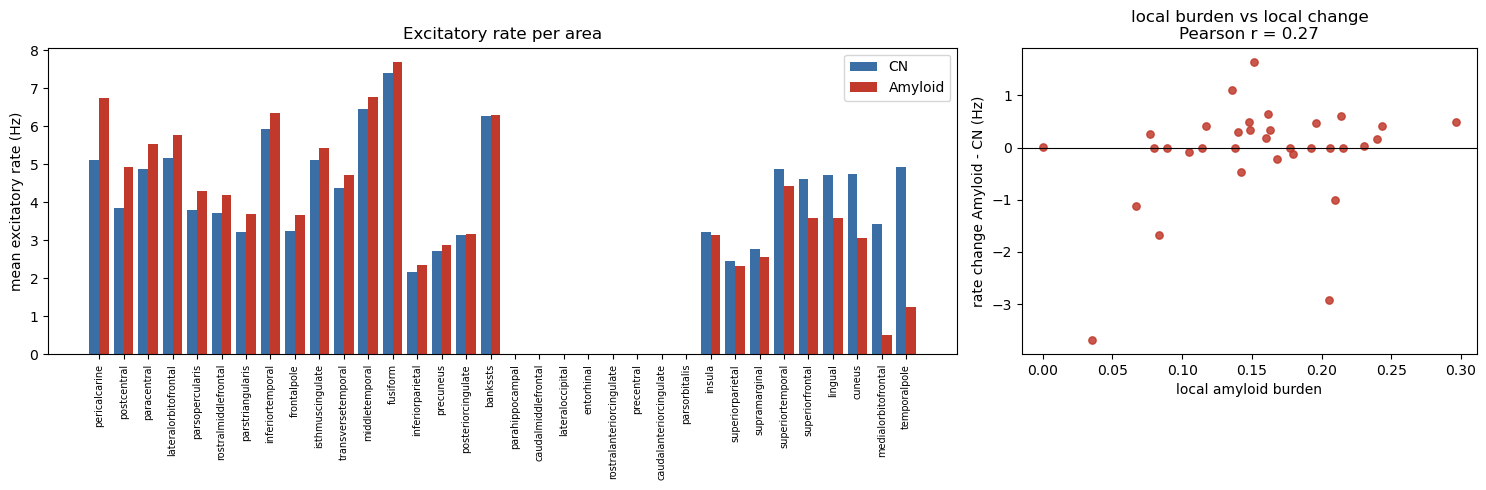

In [36]:
e_cn = area_mean_rate("tutorial_CN", "E")
e_ad = area_mean_rate("tutorial_amyloid", "E")
burden = amyloid_burden().reindex(e_cn.index).fillna(0.0)
delta = e_ad - e_cn
order = delta.sort_values(ascending=False).index

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [2, 1]})
x = np.arange(len(order))
axes[0].bar(x - 0.2, e_cn.loc[order], width=0.4, color="#3b6ea5", label="CN")
axes[0].bar(x + 0.2, e_ad.loc[order], width=0.4, color="#c0392b", label="Amyloid")
axes[0].set_xticks(x); axes[0].set_xticklabels(order, rotation=90, fontsize=7)
axes[0].set_ylabel("mean excitatory rate (Hz)")
axes[0].set_title("Excitatory rate per area"); axes[0].legend()

axes[1].scatter(burden.loc[order], delta.loc[order], s=28, c="#c0392b", alpha=0.85)
axes[1].axhline(0, c="k", lw=0.8)
axes[1].set_xlabel("local amyloid burden")
axes[1].set_ylabel("rate change Amyloid - CN (Hz)")
axes[1].set_title("local burden vs local change\n"
                  f"Pearson r = {np.corrcoef(burden.loc[order], delta.loc[order])[0, 1]:.2f}")
plt.tight_layout(); plt.show()

The left panel shows the excitatory rate of every area in both conditions, the right panel the change
of each area against its local amyloid burden. In this run the changes have both signs and are only
weakly related to the local burden (Pearson r in the panel title). With the caveats of B.5, the
figure shows how to look for a regional effect, not what that effect is.

The pipeline's own figures make the same comparison per area - compare the two area overviews - and
the neuron-type raster colours every type declared in `neuron_types` - here the amyloid-affected
neurons - separately from the healthy ones.

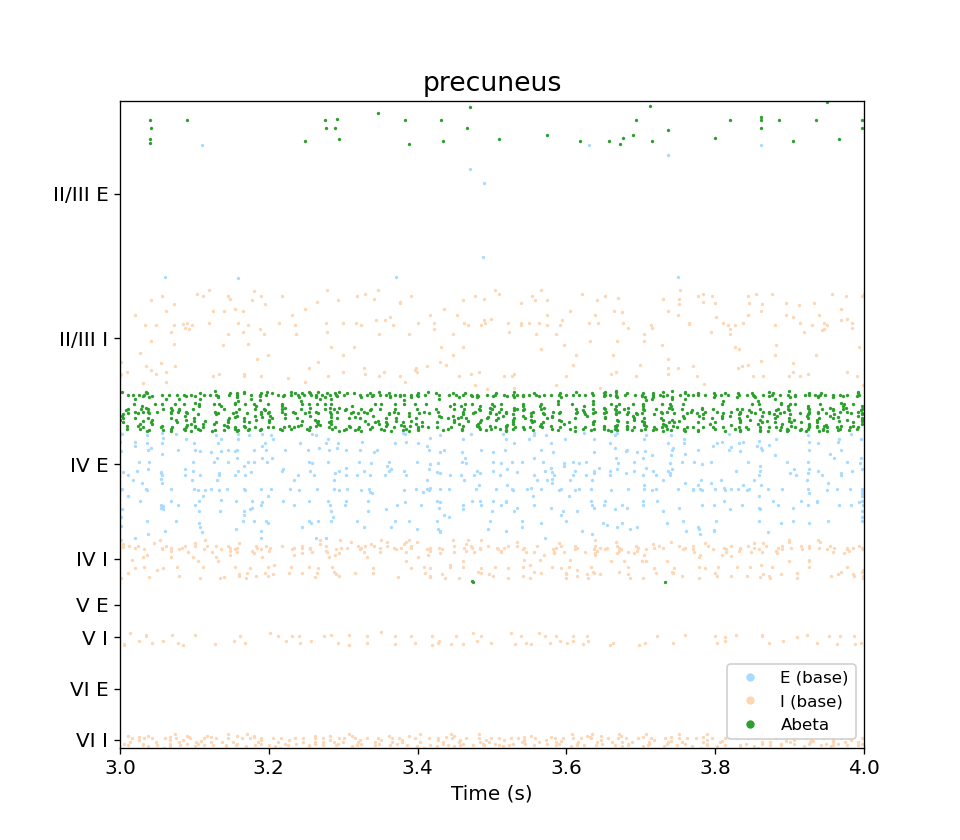

In [37]:
show("tutorial_amyloid", "raster/raster_neuron_types_precuneus.png", width=680)

## B.7 Seeds really matter

Everything so far comes from `master_seed = 2903`. The seed sets the connectivity draw, the weight
and delay draws, the Poisson background and the initial membrane potentials - so a different seed is
*a different sample of the same statistical model*. The seed-to-seed spread is the noise floor
against which any claimed effect must be judged. In our practice, different seeds sometimes lead to quite different results.

Each extra seed is a run of its own, `tutorial_CN_seed1234` and so on, started from scratch like
every laptop run: its network is built again rather than borrowed from `tutorial_CN`, then simulated;
the analysis stage is skipped and the rates are read straight from the spike files. Changing only
`master_seed` leaves `net_params` untouched, so the rebuilt network gets **the same network hash** -
the hash is a function of the parameters, not of the run. Two extra seeds per condition, about
7 minutes.

In [38]:
RUN_SEED_CHECK = True
EXTRA_SEEDS = [1234, 5678]

# rates_for_seed() runs the experiment again with another master_seed, as its own
# run results/<experiment>_seed<seed>/: network and simulation from scratch, then the
# rates straight from the spike files.
rows = []
if RUN_SEED_CHECK:
    for label, experiment in [("CN", "tutorial_CN"), ("Amyloid", "tutorial_amyloid")]:
        for seed in [master_seed(experiment)] + EXTRA_SEEDS:
            r = rates_for_seed(experiment, seed)
            rows.append(dict(condition=label, seed=seed,
                             E_rate=r.xs("E", level=pop_level(r)).mean()))
    seeds_df = pd.DataFrame(rows)
    display(seeds_df.round(3))

    # Rebuilt, not reused - and still the same network, because net_params is the same.
    for experiment in ("tutorial_CN", "tutorial_amyloid"):
        same = all(hashes(f"{experiment}_seed{seed}")["network"] == hashes(experiment)["network"]
                   for seed in EXTRA_SEEDS)
        print(f"{experiment}: every seed rebuilt the same network hash -> {same}")
else:
    print("Seed check skipped.")

,condition,seed,E_rate
0,CN,2903,3.536
1,CN,1234,3.442
2,CN,5678,3.426
3,Amyloid,2903,3.428
4,Amyloid,1234,3.402
5,Amyloid,5678,3.327


tutorial_CN: every seed rebuilt the same network hash -> True
tutorial_amyloid: every seed rebuilt the same network hash -> True


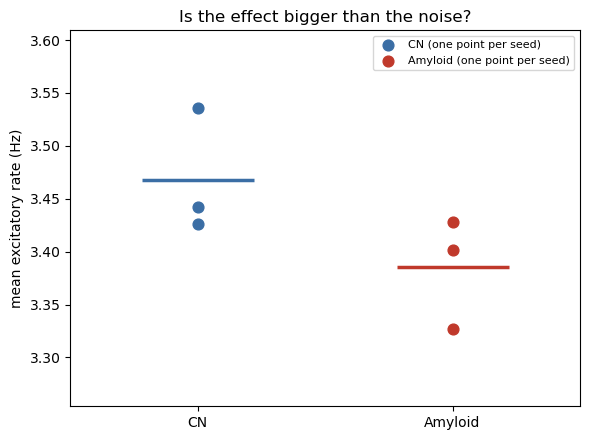

CN 3.468 +/- 0.059 Hz
Amyloid 3.386 +/- 0.053 Hz
difference -0.082 Hz = 1.4 x the seed spread

(3 seeds is the smallest number that gives a spread at all; a real analysis uses 10-20.)


In [39]:
if RUN_SEED_CHECK:
    fig, ax = plt.subplots(figsize=(6, 4.5))
    for x, (cond, color) in enumerate([("CN", "#3b6ea5"), ("Amyloid", "#c0392b")]):
        v = seeds_df.loc[seeds_df.condition == cond, "E_rate"].values
        ax.scatter(np.full_like(v, x, dtype=float), v, s=60, color=color, zorder=3,
                   label=f"{cond} (one point per seed)")
        ax.hlines(v.mean(), x - 0.22, x + 0.22, color=color, lw=2.5, zorder=2)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["CN", "Amyloid"]); ax.set_xlim(-0.5, 1.5)
    ax.set_ylabel("mean excitatory rate (Hz)")
    ax.set_title("Is the effect bigger than the noise?")
    ax.legend(fontsize=8); ax.margins(y=0.35)
    plt.tight_layout(); plt.show()

    cn = seeds_df.loc[seeds_df.condition == "CN", "E_rate"].values
    ad = seeds_df.loc[seeds_df.condition == "Amyloid", "E_rate"].values
    spread = max(cn.std(ddof=1), ad.std(ddof=1))
    effect = ad.mean() - cn.mean()
    print(f"CN {cn.mean():.3f} +/- {cn.std(ddof=1):.3f} Hz")
    print(f"Amyloid {ad.mean():.3f} +/- {ad.std(ddof=1):.3f} Hz")
    print(f"difference {effect:+.3f} Hz = {abs(effect) / spread:.1f} x the seed spread")
    print("\n(3 seeds is the smallest number that gives a spread at all; "
          "a real analysis uses 10-20.)")

## B.8 Customised amyloid load

The slots of 5.1 point a copy of an experiment at one participant's connectome and BOLD; the
amyloid map is a third slot. Copy `experiments/tutorial_amyloid.py` - it already declares the
`"Abeta"` type - and point all three at the files shipped in `model/experimental_data/amyloid/`:

```python
_AMYLOID = os.path.join(_HERE, "..", "model", "experimental_data", "amyloid")
net_params["predictive_connectomic_params"] = {"con_path": os.path.join(_AMYLOID, "amyloid_SC.mat")}
net_params["neuron_types"]["Abeta"]["ratio_E"] = os.path.join(_AMYLOID, "amyloid_ratio.csv")
ana_params["experimental_fc"] = os.path.join(_AMYLOID, "amyloid_bold.npy")
```

The connectome and the BOLD belong to one ADNI participant, the amyloid map to another; for a fully
individual model, replace the map with that person's own, in the same CSV format (`area,layer,ratio`).

Check the map the way 5.5 checks the other two files, regenerate the full-scale rates for the copy
(5.6), and re-check the working point before anything else - the amyloid neurons sit 10 mV closer to
threshold, so they move it more than a new connectome does. The copy takes its drive from
`tutorial_CN.py` (the `_CN` line); with an individual connectome its healthy control is a copy of
`tutorial_CN.py` with the same `con_path`, calibrated as in 5.6 - point the `_CN` line at that file.


In [40]:
check_data(MODEL_ROOT / "experimental_data" / "amyloid" / "amyloid_ratio.csv")


amyloid_ratio.csv
  columns   : ['area', 'layer', 'ratio']
  areas     : 33 named + a default row, ratio in [0.000, 0.296]
  -> usable as it stands


True

---

# Appendix C - Troubleshooting

| Symptom | Likely cause | Fix |
|---|---|---|
| `The bundled model is missing` | the notebook was moved away from its folder | run it from the tutorial folder, so `model/` sits beside it |
| `ModuleNotFoundError: No module named 'nest'` | wrong kernel, or NEST not installed | **check the kernel selector**; `python -c "import nest"` in the same environment. On Windows you must be inside WSL2 |
| A stage raises `FileNotFoundError` for `experimental_data/...` | the subprocess ran in the wrong directory | `run_stage` passes `cwd=MODEL_ROOT`; do not change that - the repository resolves data paths from the working directory |
| Mean firing rate is ~0 | working point not calibrated | 5.6: `eta_search()`, then `fullscale_rates()` |
| Rates look plausible but nothing changes when you edit a parameter | you edited a different file, or the hash did not change | check `hashes(...)` before and after; a changed `net_params` must change the network hash |
| `no completed run 'tutorial_CN'` | a reader was called before `run_all`, or the run failed midway | `run_all("tutorial_CN")`; a failed stage names its log in `results/<run>/log/` |
| `not found: figures/fullscale/...` | the figures of 6.2 are missing from your copy | they ship in `figures/fullscale/`; restore that folder from the repository |
| Kernel dies during the simulate stage | out of RAM | lower `N_scaling` in the experiment file (Part 2) |
| A cell runs for many minutes with no output | swapping to disk | same as above |
| `TypeError: Type of specific_dict[x] ... dont match` | an override has a different type from the default it replaces | usually an `int` where the default is a `float`, or vice versa |
| `ValueError: unknown area ...` | area name not in the DK list | lower-case, no spaces, e.g. `superiorfrontal` |
| `ValueError: neuron_types[...]` | unknown key in a type, ratios of all types summing to more than 1, or the reserved name `base` | the message names the type and the key; allowed keys are `ratio_X`, `neuron_model_X`, `neuron_params_X`, `neuron_param_dist_X` |
| Figures look empty | matplotlib style file not found | the analysis stage resolves it relative to the repository root; it must run with `cwd=MODEL_ROOT` |

### Starting over

```python
import shutil
shutil.rmtree(RESULTS, ignore_errors=True)               # all laptop runs
```

Each run keeps its stage markers inside its own `results/<run>/`, so that is everything. The
imported full-scale run in `fullscale/` and the model repository are never touched by any of this.